In [ ]:
# ==============================================================================
# PROJET ACADÉMIQUE COMPLET — VERSION DÉFINITIVE
# Prévision de la consommation électrique française à J+1
#
# Ce script reprend la logique du notebook :
# - Eco2mix national semi-horaire -> horaire ;
# - météo Open-Meteo agrégée à partir de 8 villes françaises pondérées ;
# - variables calendaires, fériés, ponts, retards et moyennes glissantes ;
# - thermosensibilité journalière ;
# - sélection du jeu de variables sur la validation 2023 ;
# - sélection du modèle sur la validation 2023 ;
# - test final sur 2024 ;
# - correction de biais glissante ;
# - scénarios de météo bruitée ;
# - SARIMAX et Prophet comme modèles comparatifs ;
# - backtest annuel, périodes de rupture, placebo et bootstrap.

In [24]:
# ============================================================
# IMPORTATION DES BIBLIOTHÈQUES
# ============================================================

from google.colab import drive
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import requests, time
import statsmodels.api as sm
import holidays
import xgboost as xgb
import warnings, time
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance

In [4]:
# Monter Google Drive dans l'environnement de travail Colab
# Cela permet d'accéder aux fichiers stockés dans mon Drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
# Définir le chemin source et le chemin de destination sur Google Drive
source_path = '/content/eco2mix-national-cons-def.csv'
destination_path = '/content/drive/MyDrive/eco2mix-national-cons-def.csv'

# Essayer d'effectuer la copie du fichier
try:
    # Copier le fichier source vers le chemin de destination
    shutil.copy(source_path, destination_path)

    # Afficher un message si la copie s'est déroulée correctement
    print("Le fichier a été copié avec succès sur votre Google Drive !")

# Intercepter une éventuelle erreur pendant la copie
except Exception as e:
    # Afficher le détail de l'erreur rencontrée
    print(f"Une erreur est survenue lors de la copie : {e}")

Une erreur est survenue lors de la copie : [Errno 2] No such file or directory: '/content/eco2mix-national-cons-def.csv'


In [6]:
# Paramètres d'affichage
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 150)

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True

In [7]:
# ============================================================
# IMPORTATION DES BIBLIOTHÈQUES
# ============================================================

# Chemin du fichier sur Google Drive
drive_file_path = '/content/drive/MyDrive/eco2mix-national-cons-def.csv'

# Chargement du fichier dans base_data avec le séparateur ';'
base_data = pd.read_csv(drive_file_path, sep=';')

print("========== DONNÉES BRUTES ==========")
print("Dimensions :", base_data.shape)
print("\nColonnes disponibles :")
print(base_data.columns.tolist())

print("\nPremières lignes :")
display(base_data.head())

/tmp/ipykernel_2540/67800810.py:5: DtypeWarning: Columns (23,28) have mixed types. Specify dtype option on import or set low_memory=False.
  base_data = pd.read_csv(drive_file_path, sep=';')


========== DONNÉES BRUTES ==========
Dimensions : (514272, 37)

Colonnes disponibles :
['Périmètre', 'Nature', 'Date', 'Heure', 'Date et Heure', 'Consommation (MW)', 'Prévision J-1 (MW)', 'Prévision J (MW)', 'Fioul (MW)', 'Charbon (MW)', 'Gaz (MW)', 'Nucléaire (MW)', 'Eolien (MW)', 'Solaire (MW)', 'Hydraulique (MW)', 'Pompage (MW)', 'Bioénergies (MW)', 'Ech. physiques (MW)', 'Taux de CO2 (g/kWh)', 'Ech. comm. Angleterre (MW)', 'Ech. comm. Espagne (MW)', 'Ech. comm. Italie (MW)', 'Ech. comm. Suisse (MW)', 'Ech. comm. Allemagne-Belgique (MW)', 'Fioul - TAC (MW)', 'Fioul - Cogénération (MW)', 'Fioul - Autres (MW)', 'Gaz - TAC (MW)', 'Gaz - Cogénération (MW)', 'Gaz - CCG (MW)', 'Gaz - Autres (MW)', "Hydraulique - Fil de l'eau + éclusée (MW)", 'Hydraulique - Lacs (MW)', 'Hydraulique - STEP turbinage (MW)', 'Bioénergies - Déchets (MW)', 'Bioénergies - Biomasse (MW)', 'Bioénergies - Biogaz (MW)']

Premières lignes :


,Périmètre,Nature,Date,Heure,Date et Heure,Consommation (MW),Prévision J-1 (MW),Prévision J (MW),Fioul (MW),Charbon (MW),Gaz (MW),Nucléaire (MW),Eolien (MW),Solaire (MW),Hydraulique (MW),...,Ech. comm. Suisse (MW),Ech. comm. Allemagne-Belgique (MW),Fioul - TAC (MW),Fioul - Cogénération (MW),Fioul - Autres (MW),Gaz - TAC (MW),Gaz - Cogénération (MW),Gaz - CCG (MW),Gaz - Autres (MW),Hydraulique - Fil de l'eau + éclusée (MW),Hydraulique - Lacs (MW),Hydraulique - STEP turbinage (MW),Bioénergies - Déchets (MW),Bioénergies - Biomasse (MW),Bioénergies - Biogaz (MW)
0,France,Données consolidées,2026-08-31,23:45,2026-08-31T21:45:00+00:00,NaN,42850,42250,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,747.0,1315,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,France,Données consolidées,2026-08-31,23:30,2026-08-31T21:30:00+00:00,43979.0,44200,43000,55.0,15.0,3219.0,37002.0,3758.0,1.0,4311.0,...,759.0,1541,13.0,39.0,3.0,27.0,172.0,2969.0,51.0,2225.0,1405.0,681.0,485.0,403.0,291.0
2,France,Données consolidées,2026-08-31,23:15,2026-08-31T21:15:00+00:00,NaN,44850,43750,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,721.0,831,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,France,Données consolidées,2026-08-31,23:00,2026-08-31T21:00:00+00:00,45070.0,45500,44500,55.0,15.0,3270.0,36863.0,3912.0,2.0,4953.0,...,722.0,808,13.0,39.0,3.0,26.0,177.0,3016.0,51.0,2278.0,1869.0,806.0,484.0,402.0,292.0
4,France,Données consolidées,2026-08-31,22:45,2026-08-31T20:45:00+00:00,NaN,45100,44150,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,828.0,1060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
# ============================================================
# NETTOYAGE DES DONNEES
# ============================================================

#Repérer les doublons d’horodatage
dup = base_data[base_data.duplicated(subset="Date et Heure", keep=False)].sort_values("Date et Heure")

print(len(dup), "lignes en doublon")
dup[["Date", "Heure", "Date et Heure", "Consommation (MW)", "Eolien (MW)"]]

120 lignes en doublon


,Date,Heure,Date et Heure,Consommation (MW),Eolien (MW)
506199,2012-03-25,03:00,2012-03-25T01:00:00+00:00,46435.0,1225.0
506198,2012-03-25,02:00,2012-03-25T01:00:00+00:00,46435.0,1225.0
506196,2012-03-25,02:15,2012-03-25T01:15:00+00:00,NaN,NaN
506197,2012-03-25,03:15,2012-03-25T01:15:00+00:00,NaN,NaN
506194,2012-03-25,03:30,2012-03-25T01:30:00+00:00,46383.0,1183.0
...,...,...,...,...,...
14964,2026-03-29,02:15,2026-03-29T01:15:00+00:00,NaN,NaN
14963,2026-03-29,03:30,2026-03-29T01:30:00+00:00,53875.0,9424.0
14962,2026-03-29,02:30,2026-03-29T01:30:00+00:00,54750.0,10295.0
14961,2026-03-29,02:45,2026-03-29T01:45:00+00:00,NaN,NaN


In [7]:
# ============================================================
# NETTOYAGE DES DONNEES
# ============================================================

#Repérer les doublons d’horodatage

cmp_cols = ["Consommation (MW)", "Eolien (MW)", "Solaire (MW)"]

# 1. Lignes dont "Date et Heure" apparaît plusieurs fois
dup = (base_data[base_data.duplicated(subset="Date et Heure", keep=False)]
       .sort_values(["Date et Heure", "Heure"]))
print(len(dup), "lignes en doublon,", dup["Date et Heure"].nunique(), "horodatages")

# 2. Par colonne : combien de doublons identiques / différents
for c in cmp_cols:
    nb = dup.groupby("Date et Heure")[c].nunique(dropna=False)
    print(f"{c:20s} | identiques : {(nb == 1).sum():3d} | différentes : {(nb > 1).sum():3d}")

# 3. Afficher uniquement les lignes où au moins une colonne diffère
nb = dup.groupby("Date et Heure")[cmp_cols].nunique(dropna=False)
diff = nb[(nb > 1).any(axis=1)].index
detail = dup[dup["Date et Heure"].isin(diff)]
print("\nHorodatages avec au moins une différence :", len(diff))
display(detail[["Date", "Heure", "Date et Heure"] + cmp_cols])


120 lignes en doublon, 60 horodatages
Consommation (MW)    | identiques :  49 | différentes :  11
Eolien (MW)          | identiques :  49 | différentes :  11
Solaire (MW)         | identiques :  60 | différentes :   0

Horodatages avec au moins une différence : 11


,Date,Heure,Date et Heure,Consommation (MW),Eolien (MW),Solaire (MW)
506195,2012-03-25,02:30,2012-03-25T01:30:00+00:00,47196.0,1271.0,0.0
506194,2012-03-25,03:30,2012-03-25T01:30:00+00:00,46383.0,1183.0,0.0
470578,2013-03-31,02:30,2013-03-31T01:30:00+00:00,62765.0,1946.0,0.0
470579,2013-03-31,03:30,2013-03-31T01:30:00+00:00,62694.0,1925.0,0.0
435635,2014-03-30,02:30,2014-03-30T01:30:00+00:00,48737.0,2318.0,-1.0
435634,2014-03-30,03:30,2014-03-30T01:30:00+00:00,47855.0,2205.0,-1.0
400691,2015-03-29,02:30,2015-03-29T01:30:00+00:00,52852.0,6579.0,0.0
400690,2015-03-29,03:30,2015-03-29T01:30:00+00:00,52100.0,6439.0,0.0
365747,2016-03-27,02:30,2016-03-27T01:30:00+00:00,52243.0,5183.0,-1.0
365746,2016-03-27,03:30,2016-03-27T01:30:00+00:00,51335.0,4903.0,-1.0


In [9]:
# 1. Horodatage UTC et tri
base_data["datetime"] = pd.to_datetime(base_data["Date et Heure"], utc=True)
base_data = base_data.sort_values("datetime").reset_index(drop=True)

# 2. Période d'étude : avant le 01/01/2025 (heure de Paris)
limite = pd.Timestamp("2025-01-01 00:00", tz="Europe/Paris")
base_data = base_data[base_data["datetime"] < limite].reset_index(drop=True)

# 3. Suppression des lignes fictives de mars (02:00-02:45 locale, heure inexistante)
loc = base_data["datetime"].dt.tz_convert("Europe/Paris")
faux = ((loc.dt.strftime("%Y-%m-%d") != base_data["Date"].astype(str)) |
        (loc.dt.strftime("%H:%M") != base_data["Heure"].astype(str)))
print("Lignes fictives supprimées :", faux.sum())                       # attendu : 52
base_data = base_data[~faux].reset_index(drop=True)
assert base_data["datetime"].is_unique, "Il reste des doublons"
print("Lignes après nettoyage :", len(base_data))                       # attendu : 455852

# 4. Colonnes utiles
cols = {
    "Consommation (MW)": "conso",
    "Prévision J-1 (MW)": "prev_j1",
    "Eolien (MW)": "eolien",
    "Solaire (MW)": "solaire",
    "Nucléaire (MW)": "nucleaire",
    "Hydraulique (MW)": "hydro",
    "Bioénergies (MW)": "bio",
    "Gaz (MW)": "gaz",
    "Taux de CO2 (g/kWh)": "co2",
}
df = base_data.set_index("datetime")[list(cols)].rename(columns=cols)
df = df.apply(pd.to_numeric, errors="coerce")      # "ND" et autres textes deviennent NaN

# 5. Pas horaire (moyenne des quarts d'heure disponibles)
dfh = df.resample("h").mean()
print("Heures :", len(dfh))                                             # attendu : 113976
print("Manquants avant interpolation :\n", dfh.isna().sum())

# 6. Combler les 13 heures perdues en octobre
dfh = dfh.interpolate(limit=3)

# 7. Solaire : valeurs négatives de nuit remises à zéro
print("Solaire < 0 :", (dfh["solaire"] < 0).sum(), "heures")
dfh["solaire"] = dfh["solaire"].clip(lower=0)

# 8. Heure de Paris pour la suite (calendrier, graphiques)
dfh.index = dfh.index.tz_convert("Europe/Paris")

# 9. Contrôles finaux
assert len(dfh) == 113976, f"Nombre d'heures inattendu : {len(dfh)}"
print("\nManquants après nettoyage :\n", dfh.isna().sum())
print("Période :", dfh.index.min(), "->", dfh.index.max())
print("Pas régulier :", (dfh.index.to_series().diff().dropna() != pd.Timedelta("1h")).sum(), "écarts anormaux (heure locale)")
dfh.describe().round(0)

Lignes fictives supprimées : 52
Lignes après nettoyage : 455852
Heures : 113976
Manquants avant interpolation :
 conso        13
prev_j1      13
eolien       13
solaire      13
nucleaire    13
hydro        13
bio          13
gaz          13
co2          13
dtype: int64
Solaire < 0 : 18656 heures

Manquants après nettoyage :
 conso        0
prev_j1      0
eolien       0
solaire      0
nucleaire    0
hydro        0
bio          0
gaz          0
co2          0
dtype: int64
Période : 2012-01-01 00:00:00+01:00 -> 2024-12-31 23:00:00+01:00
Pas régulier : 0 écarts anormaux (heure locale)


,conso,prev_j1,eolien,solaire,nucleaire,hydro,bio,gaz,co2
count,113976.0,113976.0,113976.0,113976.0,113976.0,113976.0,113976.0,113976.0,113976.0
mean,53174.0,52744.0,3411.0,1340.0,42388.0,7154.0,1018.0,3346.0,44.0
std,11792.0,11764.0,3076.0,2260.0,7773.0,2797.0,188.0,2469.0,24.0
min,29364.0,27712.0,23.0,0.0,19231.0,1414.0,442.0,244.0,7.0
25%,44240.0,43849.0,1266.0,0.0,37803.0,5021.0,901.0,1019.0,26.0
50%,51391.0,50938.0,2388.0,35.0,41943.0,6937.0,1070.0,2884.0,40.0
75%,61059.0,60525.0,4521.0,1911.0,47331.0,9024.0,1152.0,4956.0,60.0
max,101650.0,99975.0,19728.0,16417.0,61686.0,17827.0,2172.0,10565.0,140.0


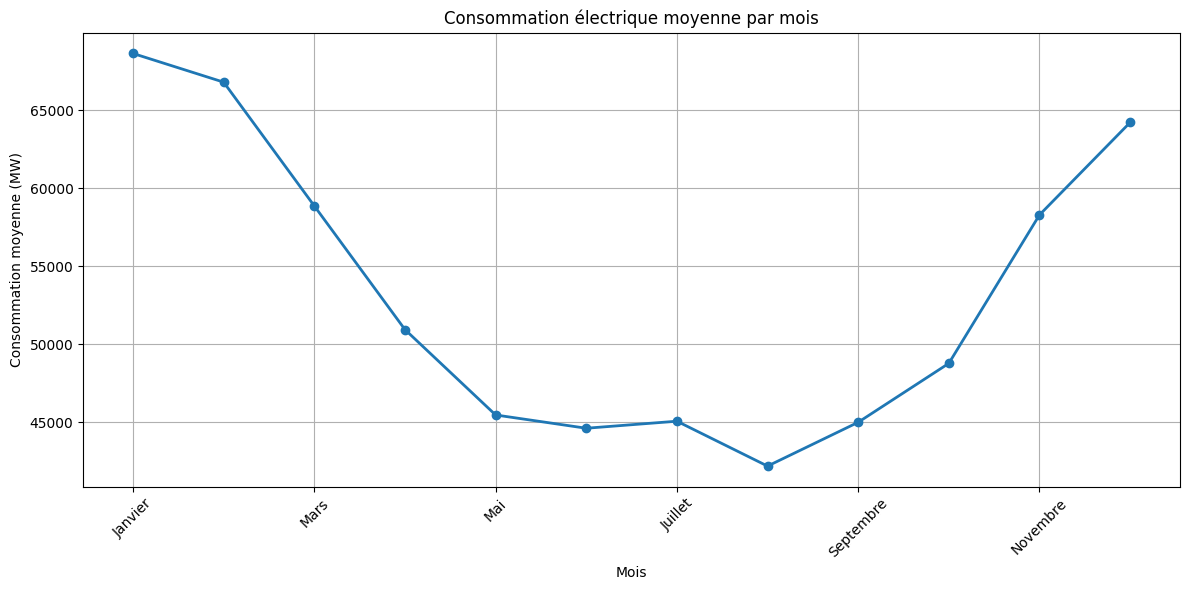

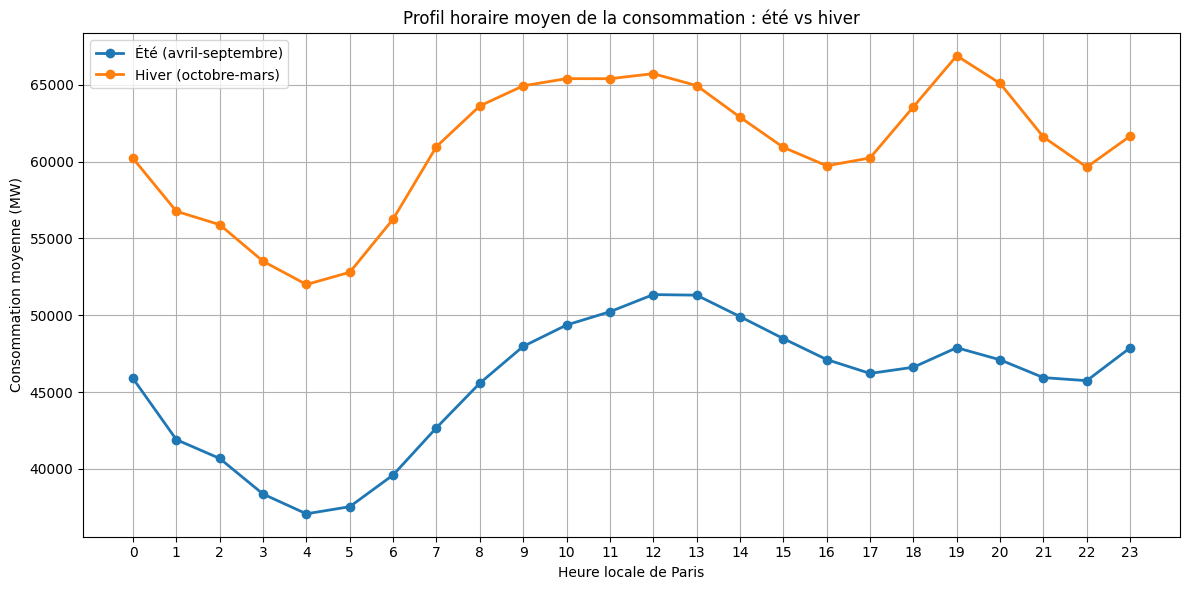

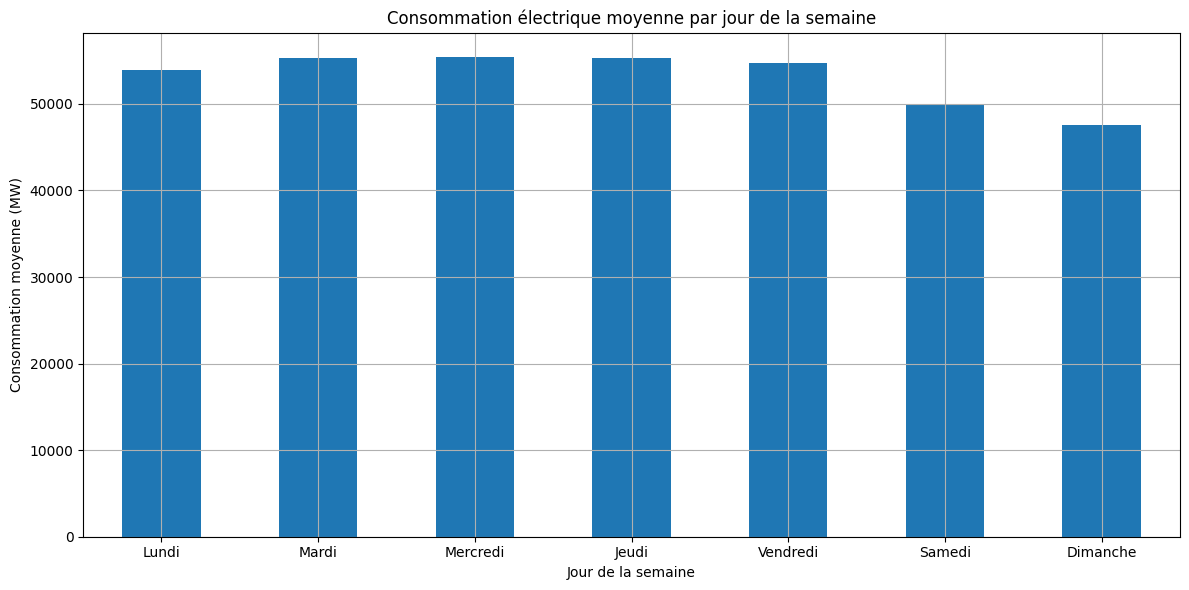

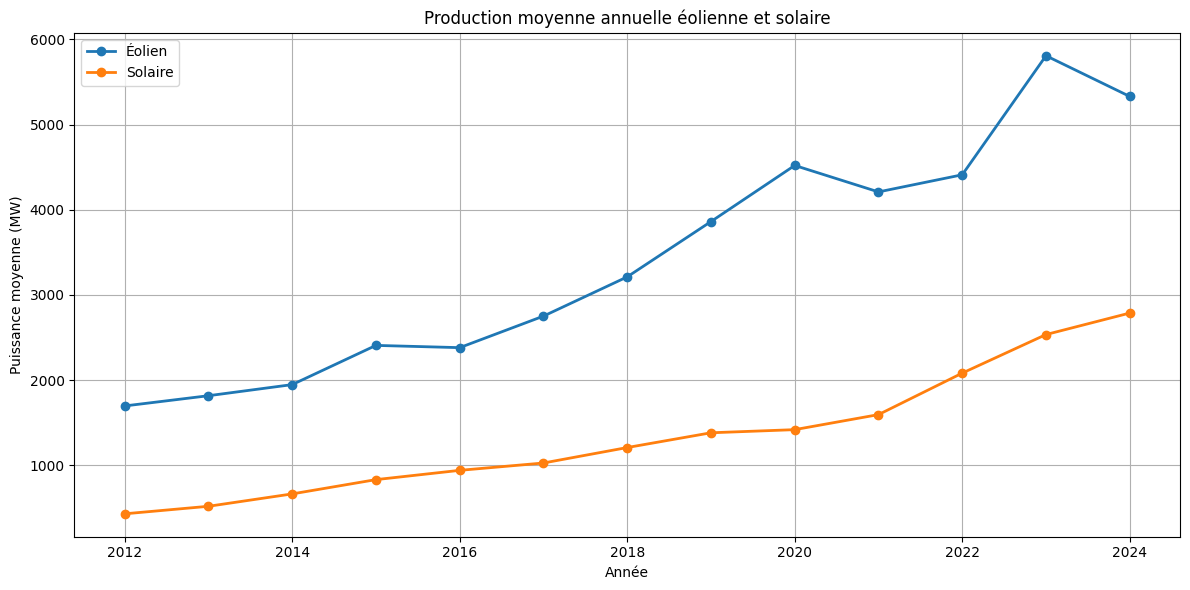

In [10]:
# ============================================================
# PRÉPARATION DES DONNÉES POUR LES GRAPHIQUES
# ============================================================

# Les analyses graphiques utilisent les valeurs disponibles.
# Les NaN sont ignorés dans les moyennes par pandas.

# On ajoute des variables calendaires locales :
# mois, heure de la journée, jour de la semaine et année.

dfh["mois"] = dfh.index.month
dfh["heure"] = dfh.index.hour
dfh["jour_semaine"] = dfh.index.dayofweek
dfh["annee"] = dfh.index.year

noms_jours = [
    "Lundi", "Mardi", "Mercredi", "Jeudi",
    "Vendredi", "Samedi", "Dimanche"
]

noms_mois = [
    "Janvier", "Février", "Mars", "Avril",
    "Mai", "Juin", "Juillet", "Août",
    "Septembre", "Octobre", "Novembre", "Décembre"
]
# ============================================================
# GRAPHIQUE 1 — CONSOMMATION MOYENNE PAR MOIS
# ============================================================

# On calcule la consommation moyenne pour chaque mois du calendrier,
# toutes les années retenues étant regroupées.
# Exemple : moyenne des consommations de tous les mois de janvier.

conso_mensuelle = (
    dfh["conso"]
    .groupby(dfh.index.month)
    .mean()
)

conso_mensuelle.index = [
    noms_mois[m - 1]
    for m in conso_mensuelle.index
]

plt.figure()
conso_mensuelle.plot(
    marker="o",
    linewidth=2
)

plt.title("Consommation électrique moyenne par mois")
plt.xlabel("Mois")
plt.ylabel("Consommation moyenne (MW)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ============================================================
# GRAPHIQUE 2 — PROFIL HORAIRE ÉTÉ / HIVER
# ============================================================

# Pour visualiser les profils journaliers, on distingue :
# - été : avril à septembre ;
# - hiver : octobre à mars.
#
# Ce regroupement est une convention descriptive, pas une
# classification météorologique stricte.
#
# Les moyennes sont calculées à partir de l'heure locale de Paris.

mois_local = dfh.index.month

ete = dfh.loc[
    mois_local.isin([4, 5, 6, 7, 8, 9])
]

hiver = dfh.loc[
    mois_local.isin([10, 11, 12, 1, 2, 3])
]

profil_ete = ete.groupby(ete.index.hour)["conso"].mean()
profil_hiver = hiver.groupby(hiver.index.hour)["conso"].mean()

plt.figure()

plt.plot(
    profil_ete.index,
    profil_ete.values,
    marker="o",
    linewidth=2,
    label="Été (avril-septembre)"
)

plt.plot(
    profil_hiver.index,
    profil_hiver.values,
    marker="o",
    linewidth=2,
    label="Hiver (octobre-mars)"
)

plt.title("Profil horaire moyen de la consommation : été vs hiver")
plt.xlabel("Heure locale de Paris")
plt.ylabel("Consommation moyenne (MW)")
plt.xticks(range(0, 24))
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# GRAPHIQUE 3 — CONSOMMATION MOYENNE PAR JOUR DE LA SEMAINE
# ============================================================

# dayofweek : lundi = 0, ..., dimanche = 6.
# Les moyennes sont calculées sur toute la période disponible.

conso_jour = (
    dfh["conso"]
    .groupby(dfh.index.dayofweek)
    .mean()
)

conso_jour.index = [
    noms_jours[j]
    for j in conso_jour.index
]

plt.figure()
conso_jour.plot(
    kind="bar",
    rot=0
)

plt.title("Consommation électrique moyenne par jour de la semaine")
plt.xlabel("Jour de la semaine")
plt.ylabel("Consommation moyenne (MW)")
plt.tight_layout()
plt.show()


# ============================================================
# GRAPHIQUE 4 — ÉVOLUTION ANNUELLE DU VENT ET DU SOLAIRE
# ============================================================

# On calcule la moyenne annuelle de la production éolienne
# et de la production solaire.
#
# Les moyennes ignorent les valeurs manquantes. Les résultats
# restent descriptifs et dépendent de la couverture disponible.

production_annuelle = (
    dfh[["eolien", "solaire"]]
    .groupby(dfh.index.year)
    .mean()
)

plt.figure()

plt.plot(
    production_annuelle.index,
    production_annuelle["eolien"],
    marker="o",
    linewidth=2,
    label="Éolien"
)

plt.plot(
    production_annuelle.index,
    production_annuelle["solaire"],
    marker="o",
    linewidth=2,
    label="Solaire"
)

plt.title("Production moyenne annuelle éolienne et solaire")
plt.xlabel("Année")
plt.ylabel("Puissance moyenne (MW)")
plt.legend()
plt.tight_layout()
plt.show()






In [12]:
# ============================================================
# ENRICHIR LES DONNEES ELECTRIQUES AVEC DES INFORMATIONS METEO
# PROVENANT DE L'API HISTORIQUE D'OPEN-METEO
# ============================================================

# Dossier de sauvegarde sur Drive (évite de tout retélécharger après un redémarrage de Colab)
try:
    DOSSIER
except NameError:
    from google.colab import drive
    drive.mount("/content/drive")
    DOSSIER = Path("/content/drive/MyDrive/projet_electricite")
    DOSSIER.mkdir(exist_ok=True)

cache = DOSSIER / "meteo_cache"; cache.mkdir(exist_ok=True)
F_METEO = DOSSIER / "meteo_2012_2024.parquet"

URL = "https://archive-api.open-meteo.com/v1/archive"
# (latitude, longitude, poids) : poids approximatifs, somme = 1
villes = {"Paris": (48.85, 2.35, .30), "Lyon": (45.76, 4.84, .12), "Marseille": (43.30, 5.37, .12),
          "Lille": (50.63, 3.07, .10), "Toulouse": (43.60, 1.44, .10), "Nantes": (47.22, -1.55, .10),
          "Strasbourg": (48.57, 7.75, .08), "Bordeaux": (44.84, -0.58, .08)}
assert abs(sum(v[2] for v in villes.values()) - 1) < 1e-9

def meteo_ville_annee(nom, lat, lon, an):
    f = cache / f"{nom}_{an}.parquet"
    if f.exists():
        return pd.read_parquet(f)
    params = {"latitude": lat, "longitude": lon,
              "start_date": f"{an}-01-01", "end_date": f"{an}-12-31",
              "hourly": "temperature_2m,wind_speed_100m,shortwave_radiation",
              "wind_speed_unit": "ms",          # vent en m/s (sinon km/h)
              "timezone": "UTC"}
    for essai in range(6):
        r = requests.get(URL, params=params, timeout=120)
        if r.status_code == 200:
            break
        print(f"{nom} {an} : code {r.status_code}, nouvelle tentative dans {30 * (essai + 1)} s")
        time.sleep(30 * (essai + 1))            # limite d'API atteinte : on attend
    else:
        r.raise_for_status()
    h = pd.DataFrame(r.json()["hourly"])
    h["time"] = pd.to_datetime(h["time"], utc=True)
    h = h.set_index("time")
    h.to_parquet(f)
    time.sleep(1)
    return h

if F_METEO.exists():
    meteo = pd.read_parquet(F_METEO)             # relecture instantanée
else:
    meteo = None
    for nom, (lat, lon, poids) in villes.items():
        ville = pd.concat([meteo_ville_annee(nom, lat, lon, an) for an in range(2012, 2025)]).sort_index()
        meteo = ville * poids if meteo is None else meteo + ville * poids
        print(nom, "terminé")
    meteo.columns = ["temp", "vent100", "rayonnement"]
    meteo.to_parquet(F_METEO)

print(meteo.shape)                               # attendu : (113976, 3)
print(meteo.index.min(), "->", meteo.index.max())
print(meteo.isna().sum())                        # attendu : 0 partout
meteo.describe().round(1)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(113976, 3)
2012-01-01 00:00:00+00:00 -> 2024-12-31 23:00:00+00:00
temp           0
vent100        0
rayonnement    0
dtype: int64


,temp,vent100,rayonnement
count,113976.0,113976.0,113976.0
mean,13.0,5.8,150.2
std,6.9,2.0,214.5
min,-7.4,0.9,0.0
25%,7.8,4.3,0.0
50%,12.6,5.5,9.5
75%,18.0,7.0,256.3
max,36.5,16.5,904.3


In [13]:
base = dfh.copy()
base.index = base.index.tz_convert("UTC")        # même fuseau que la météo
base = base.join(meteo, how="left")
base.index = base.index.tz_convert("Europe/Paris")

mcols = ["temp", "vent100", "rayonnement"]
print("Manquants après la jointure :\n", base[mcols].isna().sum())     # 1 par colonne
print(base[base["temp"].isna()].index)                                  # 2012-01-01 00:00:00+01:00

# La météo commence à 00:00 UTC, l'éco2mix une heure plus tôt : on copie l'heure suivante
base[mcols] = base[mcols].bfill(limit=1)


Manquants après la jointure :
 temp           1
vent100        1
rayonnement    1
dtype: int64
DatetimeIndex(['2012-01-01 00:00:00+01:00'], dtype='datetime64[ns, Europe/Paris]', name='datetime', freq='h')


In [14]:
print(base.shape)                                # attendu : (113976, 12)
print(base[mcols].isna().sum())                  # attendu : 0 partout
print(base.index.min(), "->", base.index.max())
base[["conso"] + mcols].corr().round(2)

(113976, 16)
temp           0
vent100        0
rayonnement    0
dtype: int64
2012-01-01 00:00:00+01:00 -> 2024-12-31 23:00:00+01:00


,conso,temp,vent100,rayonnement
conso,1.00,-0.64,0.18,-0.07
temp,-0.64,1.00,-0.24,0.55
vent100,0.18,-0.24,1.00,-0.23
rayonnement,-0.07,0.55,-0.23,1.00


In [15]:
#Creer les variables calendaires

fr = holidays.France(years=range(2012, 2025))

j = pd.DataFrame({"date": pd.date_range("2012-01-01", "2024-12-31")})
j["dow"] = j["date"].dt.dayofweek
j["ferie"] = j["date"].dt.date.map(lambda d: d in fr)
# pont : jour ouvré collé à un férié et au week-end (lundi avant un mardi férié, vendredi après un jeudi férié)
j["pont"] = (~j["ferie"]) & (j["dow"] < 5) & (
    ((j["dow"] == 0) & j["ferie"].shift(-1, fill_value=False)) |
    ((j["dow"] == 4) & j["ferie"].shift(1, fill_value=False)))
j.index = j["date"].dt.date

jour = pd.Series(base.index.date, index=base.index)     # date locale (heure de Paris)
base["heure"] = base.index.hour
base["jour_sem"] = base.index.dayofweek
base["mois"] = base.index.month
base["ferie"] = jour.map(j["ferie"]).astype(int)
base["pont"] = jour.map(j["pont"]).astype(int)

# météo dérivée (uniquement à partir du passé : pas de fuite de données)
base["temp_lisse24"] = base["temp"].rolling(24).mean()
base["temp_lisse48"] = base["temp"].rolling(48).mean()

print(base.shape)                                       # attendu : (113976, 19)
print("Jours fériés :", base["ferie"].sum() // 24)      # attendu : environ 143 (11 par an x 13 ans)
print("Jours de pont :", base["pont"].sum() // 24)
print(base[["temp_lisse24", "temp_lisse48"]].isna().sum())   # 23 et 47 : normal, début de série


(113976, 21)
Jours fériés : 143
Jours de pont : 40
temp_lisse24    23
temp_lisse48    47
dtype: int64


In [16]:
#Contrôler les colonnes
attendues = ["conso", "prev_j1", "eolien", "solaire", "nucleaire", "hydro", "bio", "gaz", "co2",
             "temp", "vent100", "rayonnement",
             "heure", "jour_sem", "mois", "ferie", "pont", "temp_lisse24", "temp_lisse48"]

print("En plus  :", [c for c in base.columns if c not in attendues])
print("Manquantes :", [c for c in attendues if c not in base.columns])

En plus  : ['jour_semaine', 'annee']
Manquantes : []


In [17]:
print(base[["jour_semaine", "jour_sem", "annee"]].drop_duplicates().head(8))
print((base["annee"] == base.index.year).all())    # True si annee = année de l'index

                           jour_semaine  jour_sem  annee
datetime                                                
2012-01-01 00:00:00+01:00             6         6   2012
2012-01-02 00:00:00+01:00             0         0   2012
2012-01-03 00:00:00+01:00             1         1   2012
2012-01-04 00:00:00+01:00             2         2   2012
2012-01-05 00:00:00+01:00             3         3   2012
2012-01-06 00:00:00+01:00             4         4   2012
2012-01-07 00:00:00+01:00             5         5   2012
2013-01-01 00:00:00+01:00             1         1   2013
True


In [18]:
base = base.drop(columns=["jour_semaine", "annee"])
print(base.shape)                                  # attendu : (113976, 19)

(113976, 19)


3237 jours ouvrés retenus sur 4749 jours.

--- Thermosensibilité sur toute la période ---
Seuil estimé       : 15.5 °C
Pente              : 2221 MW/°C
Niveau de base     : 46128 MW
R²                 : 0.900
Nombre de jours    : 3237
IC 95 % de la pente: [2195 ; 2246] MW/°C


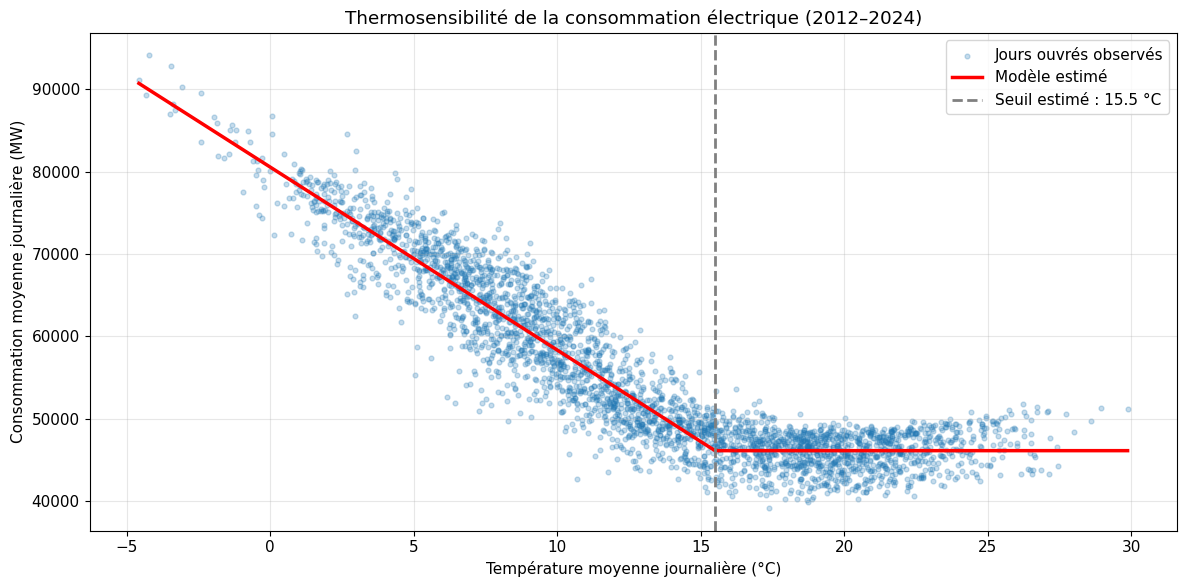

In [19]:
# ============================================================
# 0. Paramètres graphiques communs
# ============================================================
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
plt.rcParams["lines.linewidth"] = 2
plt.rcParams["font.size"] = 11

# ============================================================
# 1. Passage à une observation par jour
# ============================================================
jr = base.resample("D").agg({
    "conso": "mean",
    "temp": "mean",
    "ferie": "max",
    "pont": "max",
    "jour_sem": "first"
})

# Jours ouvrés hors jours fériés et ponts
ouvres = jr[
    (jr["ferie"] == 0)
    & (jr["pont"] == 0)
    & (jr["jour_sem"] < 5)
].dropna(subset=["conso", "temp"]).copy()

print(f"{len(ouvres)} jours ouvrés retenus sur {len(jr)} jours.")

# ============================================================
# 2. Fonction d'ajustement du modèle par morceaux
# ============================================================
def ajuster(df, seuil):
    x = np.maximum(0, seuil - df["temp"])
    X = sm.add_constant(x)
    return sm.OLS(df["conso"], X).fit()

# Recherche du seuil minimisant la somme des carrés des résidus
seuils = np.arange(12, 22.5, 0.5)

ssr = [
    ajuster(ouvres, s).ssr
    for s in seuils
]

seuil = seuils[np.argmin(ssr)]
res = ajuster(ouvres, seuil)

base_mw = res.params.iloc[0]
pente = res.params.iloc[1]
ic_pente = res.conf_int().iloc[1].tolist()

print("\n--- Thermosensibilité sur toute la période ---")
print(f"Seuil estimé       : {seuil:.1f} °C")
print(f"Pente              : {pente:.0f} MW/°C")
print(f"Niveau de base     : {base_mw:.0f} MW")
print(f"R²                 : {res.rsquared:.3f}")
print(f"Nombre de jours    : {len(ouvres)}")
print(f"IC 95 % de la pente: [{ic_pente[0]:.0f} ; {ic_pente[1]:.0f}] MW/°C")

# ============================================================
# 3. Graphique : consommation et seuil de chauffage
# ============================================================
t = np.linspace(ouvres["temp"].min(), ouvres["temp"].max(), 300)

conso_estimee = base_mw + pente * np.maximum(0, seuil - t)

fig, ax = plt.subplots(figsize=(12, 6))

ax.scatter(
    ouvres["temp"],
    ouvres["conso"],
    s=12,
    alpha=0.25,
    label="Jours ouvrés observés"
)

ax.plot(
    t,
    conso_estimee,
    color="red",
    linewidth=2.5,
    label="Modèle estimé"
)

ax.axvline(
    seuil,
    color="gray",
    linestyle="--",
    linewidth=2,
    label=f"Seuil estimé : {seuil:.1f} °C"
)

ax.set_title("Thermosensibilité de la consommation électrique (2012–2024)")
ax.set_xlabel("Température moyenne journalière (°C)")
ax.set_ylabel("Consommation moyenne journalière (MW)")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()



--- Comparaison par période ---
  periode   pente  base_mw   r2    n  ic_bas  ic_haut
2012-2016 2227.54 47327.67 0.93 1241 2194.17  2260.90
2017-2019 2246.75 46991.53 0.93  744 2201.68  2291.82
2020-2024 2153.21 44591.77 0.89 1252 2111.03  2195.40


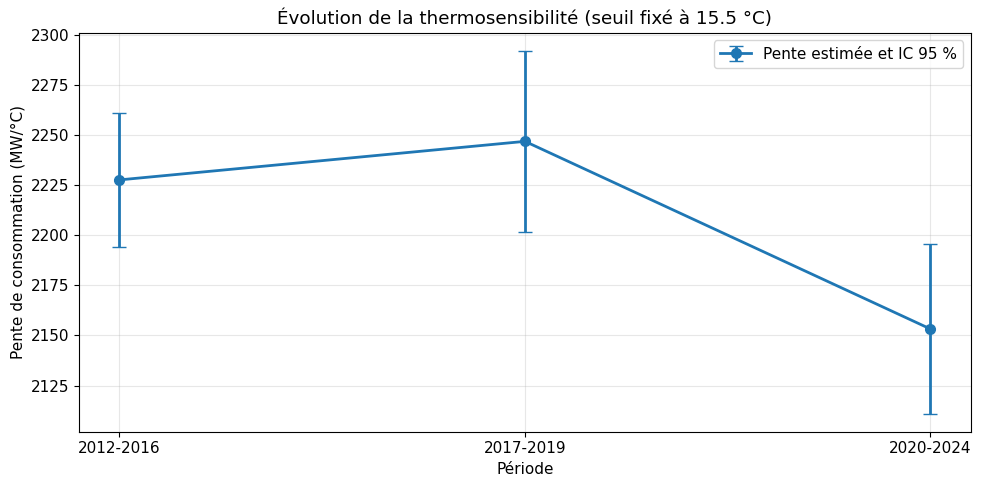

In [20]:
# ============================================================
# 4. Comparaison des pentes entre périodes
# ============================================================
periodes = [
    (2012, 2016),
    (2017, 2019),
    (2020, 2024)
]

resultats = []

for debut, fin in periodes:
    sub = ouvres[
        (ouvres.index.year >= debut)
        & (ouvres.index.year <= fin)
    ]

    r = ajuster(sub, seuil)
    ic = r.conf_int().iloc[1].tolist()

    resultats.append({
        "periode": f"{debut}-{fin}",
        "debut": debut,
        "fin": fin,
        "pente": r.params.iloc[1],
        "base_mw": r.params.iloc[0],
        "r2": r.rsquared,
        "n": len(sub),
        "ic_bas": ic[0],
        "ic_haut": ic[1]
    })

resultats = pd.DataFrame(resultats)

print("\n--- Comparaison par période ---")
print(
    resultats[
        ["periode", "pente", "base_mw", "r2", "n", "ic_bas", "ic_haut"]
    ].round(2).to_string(index=False)
)

# ============================================================
# 5. Graphique : évolution de la pente
# ============================================================
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(resultats))
pentes = resultats["pente"].to_numpy()
erreurs = np.vstack([
    pentes - resultats["ic_bas"].to_numpy(),
    resultats["ic_haut"].to_numpy() - pentes
])

ax.errorbar(
    x,
    pentes,
    yerr=erreurs,
    fmt="o-",
    capsize=5,
    markersize=7,
    linewidth=2,
    label="Pente estimée et IC 95 %"
)

ax.set_xticks(x)
ax.set_xticklabels(resultats["periode"])
ax.set_title(
    f"Évolution de la thermosensibilité "
    f"(seuil fixé à {seuil:.1f} °C)"
)
ax.set_xlabel("Période")
ax.set_ylabel("Pente de consommation (MW/°C)")
ax.legend()

plt.tight_layout()
plt.show()

In [22]:
#Examiner une éventuelle sensibilité à la chaleur
chaud = ouvres[ouvres["temp"] > 18]
for s in [21, 22, 23, 24]:
    X = sm.add_constant(np.maximum(0, chaud["temp"] - s))
    r = sm.OLS(chaud["conso"], X).fit()
    print(f"Seuil clim {s} °C : pente {r.params.iloc[1]:.0f} MW/°C (R² {r.rsquared:.3f})")

Seuil clim 21 °C : pente 396 MW/°C (R² 0.074)
Seuil clim 22 °C : pente 498 MW/°C (R² 0.071)
Seuil clim 23 °C : pente 633 MW/°C (R² 0.063)
Seuil clim 24 °C : pente 817 MW/°C (R² 0.051)


In [25]:
#Tester statistiquement les différences entre périodes

# Seuil commun aux trois périodes
seuil_froid = 15.5

df_test = ouvres.copy()
df_test["froid"] = np.maximum(0, seuil_froid - df_test["temp"])

df_test["periode"] = pd.cut(
    df_test.index.year,
    bins=[2011, 2016, 2019, 2024],
    labels=["2012-2016", "2017-2019", "2020-2024"]
)

df_test = df_test.dropna(subset=["conso", "froid", "periode"])

# La première période est la référence
modele_interaction = smf.ols(
    "conso ~ froid * C(periode)",
    data=df_test
).fit()

print(modele_interaction.summary())

# Test global : les pentes sont-elles identiques ?
test_global = modele_interaction.f_test(
    "froid:C(periode)[T.2017-2019] = 0, "
    "froid:C(periode)[T.2020-2024] = 0"
)

print("\nTest global d'égalité des pentes")
print("Statistique F :", float(test_global.fvalue))
print("p-value :", float(test_global.pvalue))


                            OLS Regression Results                            
Dep. Variable:                  conso   R-squared:                       0.919
Model:                            OLS   Adj. R-squared:                  0.919
Method:                 Least Squares   F-statistic:                     7367.
Date:                Thu, 22 Oct 2026   Prob (F-statistic):               0.00
Time:                        15:27:16   Log-Likelihood:                -30484.
No. Observations:                3237   AIC:                         6.098e+04
Df Residuals:                    3231   BIC:                         6.102e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept     

In [26]:
# =============================================================================
# QUESTION 2 - Quel modèle prévoit le mieux la consommation électrique (test : 2024) ?
#
#
#
# MÉTHODE
#   - Entraînement ≤ 2022, validation 2023, test 2024.
#   - Tous les choix (jeu de variables, algorithme, réglages, correction du biais,
#     entraînement sur météo bruitée) se font sur la VALIDATION 2023.
#   - Le modèle retenu est réentraîné sur 2012-2023 et prédit 2024 UNE seule fois.
#   - Retards de consommation >= 48 h : comparable à une prévision émise la veille.
#   - Le naïf à 24 h et le jeu D (retard 24 h) sont rapportés à part, à titre indicatif.
#
# LIMITE : la météo est observée, pas prévue. Les résultats "météo parfaite" sont
#   rétrospectifs ; la section "météo bruitée" mesure la sensibilité à ce point.
#
#
# =============================================================================

warnings.filterwarnings("ignore")

try:
    display
except NameError:
    display = print
try:
    DOSSIER
except NameError:
    DOSSIER = Path(".")
DOSSIER = Path(DOSSIER)

RAPIDE = False          # True : version réduite pour vérifier que tout tourne (quelques minutes)
SEED = 42
SIGMA_METEO = 1.5       # °C. HYPOTHÈSE d'erreur de prévision de température, à remplacer par une mesure réelle

def evaluer(y, p):
    """Erreurs d'une prévision p (positif = prévision trop haute)."""
    c = pd.concat([y.rename("y"), p.rename("p")], axis=1).dropna()
    e = c["p"] - c["y"]
    return {"n": len(c), "MAE_MW": e.abs().mean(), "RMSE_MW": np.sqrt((e ** 2).mean()),
            "MAPE_%": 100 * (e.abs() / c["y"]).mean(), "Biais_MW": e.mean(), "Ecart_type_MW": e.std()}


def dm(dif, maxlags):
    """Diebold-Mariano simplifié : les erreurs voisines sont corrélées, d'où l'écart-type HAC."""
    r = sm.OLS(np.asarray(dif, dtype=float), np.ones(len(dif))).fit(
        cov_type="HAC", cov_kwds={"maxlags": maxlags})
    return float(r.params[0]), float(r.pvalues[0])


def comparer(y, p_mod, p_ref, maxlags):
    """Gain positif = le modèle est meilleur que la référence."""
    c = pd.concat([y.rename("y"), p_mod.rename("m"), p_ref.rename("r")], axis=1).dropna()
    e_m, e_r = c["m"] - c["y"], c["r"] - c["y"]
    ga, pa = dm(e_r.abs() - e_m.abs(), maxlags)
    gq, pq = dm(e_r ** 2 - e_m ** 2, maxlags)
    return {"gain_MAE_MW": ga, "p_abs": pa, "gain_MSE_MW2": gq, "p_carre": pq}


def rapport(preds, y, ref, maxlags):
    """Tableau final : erreurs, écart à la référence (négatif = meilleur) et p-values."""
    df = pd.concat([y.rename("reel")] + [p.rename(n) for n, p in preds.items()], axis=1).dropna()
    lignes = {}
    for n in preds:
        s = evaluer(df["reel"], df[n])
        if n != ref:
            c = comparer(df["reel"], df[n], df[ref], maxlags)
            s["p_abs_vs_ref"], s["p_carre_vs_ref"] = c["p_abs"], c["p_carre"]
        lignes[n] = s
    t = pd.DataFrame(lignes).T
    t["Ecart_MAE_vs_ref_MW"] = t["MAE_MW"] - t.loc[ref, "MAE_MW"]
    t["Ecart_MAE_vs_ref_%"] = 100 * t["Ecart_MAE_vs_ref_MW"] / t.loc[ref, "MAE_MW"]
    t["Ecart_RMSE_vs_ref_%"] = 100 * (t["RMSE_MW"] - t.loc[ref, "RMSE_MW"]) / t.loc[ref, "RMSE_MW"]
    cols = ["n", "MAE_MW", "Ecart_MAE_vs_ref_MW", "Ecart_MAE_vs_ref_%", "RMSE_MW", "Ecart_RMSE_vs_ref_%",
            "MAPE_%", "Biais_MW", "Ecart_type_MW", "p_abs_vs_ref", "p_carre_vs_ref"]
    return t[[c for c in cols if c in t.columns]].sort_values("MAE_MW")


In [27]:

# %% 1. Contrôles d'entrée et variables (aucune ne regarde le futur ; retards >= 48 h)
requis = ["conso", "prev_j1", "temp", "vent100", "rayonnement", "ferie", "pont"]
manque = [c for c in requis if c not in base.columns]
assert not manque, f"Colonnes absentes de base : {manque}"

data = base[requis].copy().sort_index()
assert data.index.tz is not None, "L'index de base doit avoir un fuseau horaire"
data.index = data.index.tz_convert("Europe/Paris")
data = data[(data.index >= pd.Timestamp("2012-01-01", tz="Europe/Paris")) &
            (data.index < pd.Timestamp("2025-01-01", tz="Europe/Paris"))].copy()
assert data.index.is_unique, "Doublons dans l'index : nettoie les horodatages"
pas = data.index.to_series().diff().dropna()
assert (pas == pd.Timedelta("1h")).all(), "Index non régulier : les retards seraient faux"
for c in requis:
    data[c] = pd.to_numeric(data[c], errors="coerce")
data["ferie"] = data["ferie"].fillna(0).astype(int)
data["pont"] = data["pont"].fillna(0).astype(int)
data["cible"] = data["conso"]

# calendrier (connu à l'avance)
idx = data.index
data["jour_sem"] = idx.dayofweek
data["mois"] = idx.month
data["weekend"] = (idx.dayofweek >= 5).astype(int)
data["heure_sin"] = np.sin(2 * np.pi * idx.hour / 24)
data["heure_cos"] = np.cos(2 * np.pi * idx.hour / 24)
data["annee_sin"] = np.sin(2 * np.pi * (idx.dayofyear - 1) / 365.2425)
data["annee_cos"] = np.cos(2 * np.pi * (idx.dayofyear - 1) / 365.2425)
data["veille_ferie"] = data["ferie"].shift(-24).fillna(0)
data["lendemain_ferie"] = data["ferie"].shift(24).fillna(0)
md = idx.month * 100 + idx.day
data["fetes"] = ((md >= 1223) | (md <= 102)).astype(int)          # 23 décembre - 2 janvier
data["ferie_lag48"] = data["ferie"].shift(48)                      # le retard tombe-t-il sur un férié ?
data["ferie_lag168"] = data["ferie"].shift(168)

# mémoire de la consommation : 48 h minimum (shift AVANT rolling)
data["conso_lag48"] = data["cible"].shift(48)
data["conso_lag168"] = data["cible"].shift(168)
data["conso_moy_7j"] = data["cible"].shift(48).rolling(168).mean()
data["conso_moy_28j"] = data["cible"].shift(48).rolling(672).mean()
data["conso_lag24"] = data["cible"].shift(24)       # uniquement pour les références indicatives

In [28]:
def deriver_meteo(df, tn):
    """Toutes les variables dérivées de la température, définies à un seul endroit."""
    out = df.copy()
    out["temp"] = tn
    out["temp_lisse24"] = tn.rolling(24).mean()
    out["temp_lisse48"] = tn.rolling(48).mean()
    out["dju"] = (15.5 - tn).clip(lower=0)             # seuil de chauffage (question 1)
    out["dju_clim"] = (tn - 23).clip(lower=0)
    jn = tn.index.normalize()
    out["temp_min_jour"] = tn.groupby(jn).transform("min")
    out["temp_max_jour"] = tn.groupby(jn).transform("max")
    out["dtemp24"] = tn - tn.shift(24)
    return out

def bruiter(df, sigma, seed):
    """Simule une météo imparfaite : décalage de température aléatoire, constant sur la journée."""
    rng = np.random.default_rng(seed)
    dates = pd.Series(df.index.date, index=df.index)
    bruit = pd.Series(rng.normal(0, sigma, dates.nunique()), index=sorted(set(dates)))
    return deriver_meteo(df, df["temp"] + dates.map(bruit))


In [29]:
data = deriver_meteo(data, data["temp"])

cal = ["heure_sin", "heure_cos", "annee_sin", "annee_cos", "jour_sem", "mois", "ferie", "pont", "weekend"]
cal2 = ["veille_ferie", "lendemain_ferie", "fetes"]
lags = ["conso_lag48", "conso_lag168", "conso_moy_7j", "conso_moy_28j"]
met = ["temp", "temp_lisse24", "temp_lisse48", "dju", "dju_clim"]
met2 = ["temp_min_jour", "temp_max_jour", "dtemp24", "vent100", "rayonnement"]

JEUX = {
    "A : calendrier + retards 48 h": cal + lags,
    "B : A + météo de base": cal + lags + met,
    "E : B + météo élargie + fêtes": cal + cal2 + lags + met + met2,
    "F : E + férié sur les retards": cal + cal2 + lags + met + met2 + ["ferie_lag48", "ferie_lag168"],
    "C : calendrier + météo (sans retards)": cal + cal2 + met + met2,
    "D : E + retard 24 h (non comparable à RTE)": cal + cal2 + lags + met + met2 + ["conso_lag24"],
}
COMPARABLES = [k for k in JEUX if k[0] in "ABEF"]      # seuls jeux utilisables face à RTE
tous = sorted({c for f in JEUX.values() for c in f})
assert all(c in data.columns for c in tous)

d = data.dropna(subset=["cible"] + tous)               # mêmes lignes pour tous les jeux
tr = d[d.index.year <= 2022]
va = d[d.index.year == 2023]
te = d[d.index.year == 2024]
full = pd.concat([tr, va])
y_te = te["cible"]
print(f"Entraînement : {len(tr):,} | Validation 2023 : {len(va):,} | Test 2024 : {len(te):,}")
assert len(va) == 8760 and len(te) == 8784, "Découpage inattendu"

Entraînement : 95,713 | Validation 2023 : 8,760 | Test 2024 : 8,784


In [30]:
# %% 2. Outils de modélisation
def construire(algo, params):
    if algo == "HGB":
        return HistGradientBoostingRegressor(early_stopping=False, random_state=SEED, **params)
    return xgb.XGBRegressor(random_state=SEED, n_jobs=-1, **params)


def ajuster_predire(algo, params, poids, feats, train, test):
    """poids : poids des années >= 2018 (1 = poids égaux)."""
    m = construire(algo, params)
    m.fit(train[feats], train["cible"], sample_weight=np.where(train.index.year >= 2018, poids, 1.0))
    return pd.Series(m.predict(test[feats]), index=test.index), m


def biais_glissant(pred, reel, jours, delai=48):
    """Erreur moyenne des `jours` derniers jours CONNUS (décalage de 48 h)."""
    err = pred - reel
    return err.rolling(24 * jours, min_periods=24 * 3).mean().shift(delai).fillna(0.0)


def choisir_fenetre(p_va, reel_va):
    """Choisit sur la validation la fenêtre de correction (ou aucune)."""
    essais = {"sans correction": evaluer(reel_va, p_va)}
    for w in (7, 14, 28, 56):
        essais[f"fenêtre {w} j"] = evaluer(reel_va, p_va - biais_glissant(p_va, reel_va, w))
    t = pd.DataFrame(essais).T
    best = t["MAE_MW"].idxmin()
    return (None if best == "sans correction" else int(best.split()[1])), t



In [31]:
N_IT = 150 if RAPIDE else 600
CONF_DEFAUT = ("HGB", dict(max_iter=N_IT // 2, learning_rate=0.05, max_leaf_nodes=31,
                           l2_regularization=1.0), 1)

# %% 3. Choix du jeu de variables sur la VALIDATION 2023 (le test n'est pas utilisé)
lignes = {}
for nom, f in JEUX.items():
    p, _ = ajuster_predire(*CONF_DEFAUT, f, tr, va)
    lignes[nom] = evaluer(va["cible"], p)
choix_jeu = pd.DataFrame(lignes).T
print("VALIDATION 2023 (HistGradientBoosting, réglage par défaut)")
display(choix_jeu.round(2))
meilleur_jeu = choix_jeu.loc[COMPARABLES, "MAE_MW"].idxmin()
FEATS = JEUX[meilleur_jeu]
print("Jeu retenu (parmi A, B, E, F) :", meilleur_jeu, f"({len(FEATS)} variables)")

# %% 4. Choix de l'algorithme et des réglages sur la VALIDATION 2023
grille = []
for poids in ([1] if RAPIDE else [1, 3]):
    grille += [
        ("HGB", dict(max_iter=N_IT, learning_rate=0.05, max_leaf_nodes=31, l2_regularization=1.0), poids),
        ("HGB", dict(max_iter=N_IT, learning_rate=0.05, max_leaf_nodes=63, l2_regularization=5.0,
                     min_samples_leaf=50), poids),
        ("XGB", dict(n_estimators=N_IT, learning_rate=0.05, max_depth=6, subsample=0.8,
                     colsample_bytree=0.8), poids),
        ("XGB", dict(n_estimators=N_IT, learning_rate=0.05, max_depth=8, subsample=0.8,
                     colsample_bytree=0.7, min_child_weight=5), poids),
    ]
res_grille = []
for i, (algo, params, poids) in enumerate(grille):
    t0 = time.time()
    p, _ = ajuster_predire(algo, params, poids, FEATS, tr, va)
    res_grille.append({"id": i, "algo": algo, "poids_>=2018": poids,
                       "profondeur/feuilles": params.get("max_depth", params.get("max_leaf_nodes")),
                       **evaluer(va["cible"], p), "secondes": round(time.time() - t0)})
grille_res = pd.DataFrame(res_grille).set_index("id").sort_values("MAE_MW")
display(grille_res.round(2))
ALGO, PARAMS, POIDS = grille[int(grille_res.index[0])]
print("Réglage retenu :", ALGO, PARAMS, "| poids des années >= 2018 :", POIDS)

VALIDATION 2023 (HistGradientBoosting, réglage par défaut)


,n,MAE_MW,RMSE_MW,MAPE_%,Biais_MW,Ecart_type_MW
A : calendrier + retards 48 h,8760.0,1903.84,2606.21,3.70,771.15,2489.66
B : A + météo de base,8760.0,1632.56,2220.12,3.15,1290.53,1806.61
E : B + météo élargie + fêtes,8760.0,1589.52,2098.71,3.08,1327.99,1625.21
F : E + férié sur les retards,8760.0,1587.61,2098.11,3.08,1320.92,1630.20
C : calendrier + météo (sans retards),8760.0,3604.52,4064.81,7.11,3575.40,1933.81
D : E + retard 24 h (non comparable à RTE),8760.0,1072.89,1439.93,2.11,805.88,1193.36


Jeu retenu (parmi A, B, E, F) : F : E + férié sur les retards (28 variables)


,algo,poids_>=2018,profondeur/feuilles,n,MAE_MW,RMSE_MW,MAPE_%,Biais_MW,Ecart_type_MW,secondes
id,,,,,,,,,,
6,XGB,3,6,8760,1480.88,1954.02,2.87,1268.99,1485.98,14
4,HGB,3,31,8760,1482.02,1968.76,2.87,1220.70,1544.73,18
7,XGB,3,8,8760,1515.41,2030.62,2.92,1310.66,1551.08,18
5,HGB,3,63,8760,1516.93,2010.87,2.94,1295.93,1537.67,25
3,XGB,1,8,8760,1520.71,2035.63,2.92,1330.41,1540.81,19
2,XGB,1,6,8760,1553.26,2052.13,3.00,1346.60,1548.60,11
0,HGB,1,31,8760,1577.47,2077.15,3.05,1321.56,1602.60,18
1,HGB,1,63,8760,1592.10,2090.01,3.07,1382.20,1567.78,24


Réglage retenu : XGB {'n_estimators': 600, 'learning_rate': 0.05, 'max_depth': 6, 'subsample': 0.8, 'colsample_bytree': 0.8} | poids des années >= 2018 : 3


In [27]:
# %% 5. Scénarios de météo : parfaite, bruitée (modèle entraîné propre), bruitée (entraîné bruité)
# Les tirages de bruit d'évaluation sont identiques pour S1 et S2 : la comparaison est appariée.
def scenario(sigma, entrainer_bruite):
    dn_va = bruiter(data, sigma, 1001) if sigma > 0 else data
    dn_te = bruiter(data, sigma, 1002) if sigma > 0 else data
    dn_tr = bruiter(data, sigma, 2001) if (sigma > 0 and entrainer_bruite) else data
    dn_fu = bruiter(data, sigma, 2002) if (sigma > 0 and entrainer_bruite) else data
    p_va, _ = ajuster_predire(ALGO, PARAMS, POIDS, FEATS, dn_tr.loc[tr.index], dn_va.loc[va.index])
    p_te, m = ajuster_predire(ALGO, PARAMS, POIDS, FEATS, dn_fu.loc[full.index], dn_te.loc[te.index])
    fen, t_fen = choisir_fenetre(p_va, va["cible"])           # choix sur la validation du scénario
    if fen:
        hist, reel = pd.concat([p_va, p_te]), pd.concat([va["cible"], y_te])
        p_corr = p_te - biais_glissant(hist, reel, fen).loc[te.index]
        rte_c = te["prev_j1"] - biais_glissant(d["prev_j1"], d["cible"], fen).loc[te.index]
    else:
        p_corr, rte_c = p_te.copy(), te["prev_j1"].copy()
    return {"p_va": p_va, "p_te": p_te, "p_corr": p_corr, "rte_corr": rte_c,
            "fenetre": fen, "table_fenetre": t_fen, "modele": m}


S0 = scenario(0, False)
S1 = scenario(SIGMA_METEO, False)
S2 = scenario(SIGMA_METEO, True)

print("VALIDATION 2023, météo parfaite : correction du biais glissant")
display(S0["table_fenetre"].round(2))
print("Fenêtre retenue (météo parfaite) :", S0["fenetre"] or "aucune")

mae_val_s1 = evaluer(va["cible"], S1["p_va"])["MAE_MW"]
mae_val_s2 = evaluer(va["cible"], S2["p_va"])["MAE_MW"]
ADOPTER_BRUIT = mae_val_s2 < mae_val_s1
print(f"\nValidation 2023 sur météo bruitée (sigma = {SIGMA_METEO} °C) : "
      f"MAE {mae_val_s1:.0f} MW si entraîné sur météo parfaite, {mae_val_s2:.0f} MW si entraîné sur météo bruitée")
print("Entraînement sur météo bruitée retenu :", ADOPTER_BRUIT)

# %% 6. TEST 2024 - horaire, météo parfaite (rétrospectif). Le test est lu UNE fois.
ridge = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(full[FEATS], full["cible"])
p_ridge = pd.Series(ridge.predict(te[FEATS]), index=te.index)

preds_h = {
    "Naïve 168 h": te["conso_lag168"],
    "RTE J-1": te["prev_j1"],
    "RTE corrigé (biais glissant)": S0["rte_corr"],
    "Ridge (mêmes variables)": p_ridge,
    "Modèle final": S0["p_te"],
    "Modèle final corrigé (biais glissant)": S0["p_corr"],
}
horaire = rapport(preds_h, y_te, "RTE J-1", 168)
print("TEST 2024 - HORAIRE, météo observée (rétrospectif)")
display(horaire.round(3))
horaire.to_csv(DOSSIER / "q2_horaire.csv", encoding="utf-8-sig")

# %% 7. Sensibilité à une météo imparfaite
preds_b = {
    "RTE J-1": te["prev_j1"],
    "Modèle, météo parfaite": S0["p_te"],
    "Modèle, météo bruitée (entraîné sur météo parfaite)": S1["p_te"],
    "Modèle corrigé, météo bruitée (entraîné sur météo parfaite)": S1["p_corr"],
    "Modèle, météo bruitée (entraîné sur météo bruitée)": S2["p_te"],
    "Modèle corrigé, météo bruitée (entraîné sur météo bruitée)": S2["p_corr"],
}
bruit_tab = rapport(preds_b, y_te, "RTE J-1", 168)
print(f"TEST 2024 - MÉTÉO BRUITÉE (sigma = {SIGMA_METEO} °C, hypothèse non mesurée)")
display(bruit_tab.round(3))
print("Fenêtres de correction retenues par la validation :",
      {"météo parfaite": S0["fenetre"], "bruitée, entraîné propre": S1["fenetre"],
       "bruitée, entraîné bruité": S2["fenetre"]})
bruit_tab.to_csv(DOSSIER / "q2_meteo_bruitee.csv", encoding="utf-8-sig")

# %% 8. Ce qu'apporte chaque groupe de variables (information, PAS un critère de choix)
abl = {}
for nom, f in JEUX.items():
    abl[nom], _ = ajuster_predire(ALGO, PARAMS, POIDS, f, full, te)
abl["RTE J-1"] = te["prev_j1"]
ablation = rapport(abl, y_te, "RTE J-1", 168)
print("TEST 2024 - ABLATION (même réglage pour tous)")
display(ablation.round(3))
ablation.to_csv(DOSSIER / "q2_ablation.csv", encoding="utf-8-sig")

lag24 = rapport({"Naïf lag24 (horaire glissant)": te["conso_lag24"], "RTE J-1": te["prev_j1"],
                 "Jeu D (avec retard 24 h)": abl["D : E + retard 24 h (non comparable à RTE)"]},
                y_te, "RTE J-1", 168)
print("RÉFÉRENCES AVEC RETARD 24 h - À NE PAS CONFONDRE AVEC UNE PRÉVISION ÉMISE LA VEILLE")
display(lag24.round(3))

VALIDATION 2023, météo parfaite : correction du biais glissant


,n,MAE_MW,RMSE_MW,MAPE_%,Biais_MW,Ecart_type_MW
sans correction,8760.0,1480.88,1954.02,2.87,1268.99,1485.98
fenêtre 7 j,8760.0,991.98,1317.81,1.96,33.73,1317.45
fenêtre 14 j,8760.0,994.25,1322.83,1.97,48.46,1322.02
fenêtre 28 j,8760.0,1042.83,1388.33,2.07,66.33,1386.82
fenêtre 56 j,8760.0,1067.80,1448.81,2.11,64.98,1447.44


Fenêtre retenue (météo parfaite) : 7

Validation 2023 sur météo bruitée (sigma = 1.5 °C) : MAE 1618 MW si entraîné sur météo parfaite, 1516 MW si entraîné sur météo bruitée
Entraînement sur météo bruitée retenu : True
TEST 2024 - HORAIRE, météo observée (rétrospectif)


,n,MAE_MW,Ecart_MAE_vs_ref_MW,Ecart_MAE_vs_ref_%,RMSE_MW,Ecart_RMSE_vs_ref_%,MAPE_%,Biais_MW,Ecart_type_MW,p_abs_vs_ref,p_carre_vs_ref
RTE corrigé (biais glissant),8784.0,1038.409,-389.820,-27.294,1344.997,-23.829,2.085,3.442,1345.069,0.0,0.000
Modèle final corrigé (biais glissant),8784.0,1047.091,-381.138,-26.686,1396.437,-20.916,2.065,2.473,1396.514,0.0,0.000
Modèle final,8784.0,1152.191,-276.038,-19.327,1542.316,-12.654,2.262,530.066,1448.450,0.0,0.006
RTE J-1,8784.0,1428.229,0.000,0.000,1765.754,0.000,2.860,-1146.229,1343.223,NaN,NaN
Ridge (mêmes variables),8784.0,1941.905,513.676,35.966,2458.948,39.258,4.036,1021.798,2236.722,0.0,0.000
Naïve 168 h,8784.0,3246.440,1818.211,127.305,4856.928,175.063,6.085,-163.204,4854.461,0.0,0.000


TEST 2024 - MÉTÉO BRUITÉE (sigma = 1.5 °C, hypothèse non mesurée)


,n,MAE_MW,Ecart_MAE_vs_ref_MW,Ecart_MAE_vs_ref_%,RMSE_MW,Ecart_RMSE_vs_ref_%,MAPE_%,Biais_MW,Ecart_type_MW,p_abs_vs_ref,p_carre_vs_ref
"Modèle, météo parfaite",8784.0,1152.191,-276.038,-19.327,1542.316,-12.654,2.262,530.066,1448.450,0.000,0.006
"Modèle corrigé, météo bruitée (entraîné sur météo parfaite)",8784.0,1397.402,-30.827,-2.158,1888.275,6.939,2.701,-7.066,1888.369,0.721,0.287
RTE J-1,8784.0,1428.229,0.000,0.000,1765.754,0.000,2.860,-1146.229,1343.223,NaN,NaN
"Modèle, météo bruitée (entraîné sur météo parfaite)",8784.0,1432.289,4.060,0.284,1934.433,9.553,2.790,595.483,1840.602,0.966,0.195
"Modèle corrigé, météo bruitée (entraîné sur météo bruitée)",8784.0,1432.352,4.123,0.289,1958.458,10.913,2.764,-43.022,1958.097,0.965,0.150
"Modèle, météo bruitée (entraîné sur météo bruitée)",8784.0,1463.027,34.798,2.436,1965.419,11.308,2.814,587.053,1875.804,0.733,0.120


Fenêtres de correction retenues par la validation : {'météo parfaite': 7, 'bruitée, entraîné propre': 14, 'bruitée, entraîné bruité': 28}
TEST 2024 - ABLATION (même réglage pour tous)


,n,MAE_MW,Ecart_MAE_vs_ref_MW,Ecart_MAE_vs_ref_%,RMSE_MW,Ecart_RMSE_vs_ref_%,MAPE_%,Biais_MW,Ecart_type_MW,p_abs_vs_ref,p_carre_vs_ref
D : E + retard 24 h (non comparable à RTE),8784.0,819.047,-609.182,-42.653,1112.901,-36.973,1.616,318.551,1066.398,0.000,0.000
F : E + férié sur les retards,8784.0,1152.191,-276.038,-19.327,1542.316,-12.654,2.262,530.066,1448.450,0.000,0.006
E : B + météo élargie + fêtes,8784.0,1167.415,-260.814,-18.261,1568.754,-11.157,2.287,563.655,1464.079,0.000,0.016
B : A + météo de base,8784.0,1231.986,-196.243,-13.740,1669.660,-5.442,2.426,539.033,1580.346,0.018,0.390
RTE J-1,8784.0,1428.229,0.000,0.000,1765.754,0.000,2.860,-1146.229,1343.223,NaN,NaN
A : calendrier + retards 48 h,8784.0,2110.541,682.312,47.773,3019.965,71.030,4.026,540.317,2971.406,0.000,0.000
C : calendrier + météo (sans retards),8784.0,2604.489,1176.260,82.358,3095.483,75.307,5.060,2475.656,1858.369,0.000,0.000


RÉFÉRENCES AVEC RETARD 24 h - À NE PAS CONFONDRE AVEC UNE PRÉVISION ÉMISE LA VEILLE


,n,MAE_MW,Ecart_MAE_vs_ref_MW,Ecart_MAE_vs_ref_%,RMSE_MW,Ecart_RMSE_vs_ref_%,MAPE_%,Biais_MW,Ecart_type_MW,p_abs_vs_ref,p_carre_vs_ref
Jeu D (avec retard 24 h),8784.0,819.047,-609.182,-42.653,1112.901,-36.973,1.616,318.551,1066.398,0.0,0.0
RTE J-1,8784.0,1428.229,0.000,0.000,1765.754,0.000,2.860,-1146.229,1343.223,NaN,NaN
Naïf lag24 (horaire glissant),8784.0,2532.052,1103.823,77.286,3663.532,107.477,5.108,-39.161,3663.531,0.0,0.0


SARIMAX : {'dju': 0.939, 'dju_clim': 0.499, 'ferie': -4.527, 'pont': -2.22, 'weekend': -5.819, 's1': 2.288, 'c1': 7.379, 's2': 1.013, 'c2': 1.92, 'const': 51.277, 'ar.L1': 0.86, 'ar.S.L7': 0.576, 'sigma2': 1.643}
Convergence : True | le coefficient de dju n'est pas comparable à la pente de la question 1 (termes annuels présents)
TEST 2024 - JOURNALIER


,n,MAE_MW,Ecart_MAE_vs_ref_MW,Ecart_MAE_vs_ref_%,RMSE_MW,Ecart_RMSE_vs_ref_%,MAPE_%,Biais_MW,Ecart_type_MW,p_abs_vs_ref,p_carre_vs_ref
RTE corrigé (biais glissant),366.0,659.509,-537.147,-44.887,865.540,-39.682,1.301,3.566,866.717,0.000,0.000
Modèle final corrigé (biais glissant),366.0,886.185,-310.472,-25.945,1175.546,-18.078,1.742,2.660,1177.152,0.000,0.001
Modèle final,366.0,1017.545,-179.112,-14.968,1348.938,-5.995,1.979,529.912,1242.193,0.032,0.365
RTE J-1,366.0,1196.657,0.000,0.000,1434.957,0.000,2.410,-1146.231,864.464,NaN,NaN
SARIMAX (info jusqu'à J-2),366.0,1249.381,52.724,4.406,1677.200,16.881,2.434,304.167,1651.646,0.564,0.060
"Modèle, météo bruitée (entraîné propre)",366.0,1301.314,104.657,8.746,1755.277,22.323,2.520,595.282,1653.514,0.346,0.034
"Modèle, météo bruitée (entraîné bruité)",366.0,1322.671,126.015,10.531,1769.987,23.348,2.523,586.979,1672.109,0.281,0.022
Ridge (mêmes variables),366.0,1499.868,303.211,25.338,1899.444,32.369,3.003,1021.664,1603.470,0.007,0.001
Prophet,366.0,2644.958,1448.301,121.029,3096.100,115.762,5.618,-2035.283,2336.315,0.000,0.000
Naïve 168 h,366.0,3116.468,1919.811,160.431,4666.351,225.191,5.812,-163.127,4669.883,0.000,0.001


Tests de Diebold-Mariano (journalier ; gain positif = premier modèle meilleur)


,gain_MAE_MW,p_abs,gain_MSE_MW2,p_carre
Modèle final contre RTE J-1,179.1117,0.0317,2.394681e+05,0.3653
Modèle final corrigé (biais glissant) contre RTE corrigé (biais glissant),-226.6756,0.0000,-6.327498e+05,0.0000
"Modèle, météo bruitée (entraîné propre) contre RTE J-1",-104.6571,0.3462,-1.021894e+06,0.0338
"Modèle, météo bruitée (entraîné bruité) contre RTE J-1",-126.0147,0.2815,-1.073750e+06,0.0219
SARIMAX (info jusqu'à J-2) contre RTE J-1,-52.7243,0.5642,-7.538962e+05,0.0595
Modèle final contre SARIMAX (info jusqu'à J-2),231.8361,0.0025,9.933643e+05,0.0038
Prophet contre RTE J-1,-1448.3013,0.0000,-7.526730e+06,0.0000


MAPE journalier par mois (%) et biais par mois (MW), modèle sans correction


,modele_MAPE,rte_MAPE,modele_biais,rte_biais
datetime,,,,
1,3.14,2.64,1411.53,-1543.25
2,2.14,2.46,1014.52,-1398.74
3,2.59,2.07,218.11,-1033.25
4,2.48,3.02,-322.89,-1429.42
5,2.20,3.76,766.21,-1601.79
6,1.05,2.65,213.58,-1107.25
7,1.12,2.27,-273.39,-957.17
8,1.84,1.60,383.48,-557.38
9,1.40,2.58,297.73,-1112.81


MAPE journalier par tranche de température (%)


,modele,rte
temp,,
"(-10, 5]",2.33,2.73
"(5, 10]",2.40,2.24
"(10, 15]",2.02,2.66
"(15, 20]",1.79,2.66
"(20, 40]",1.28,1.66


Les 10 pires jours du modèle (sans correction)


,conso,modele,rte,erreur_modele,erreur_rte
datetime,,,,,
2024-01-27,56905.0,62317.0,54881.0,5412.0,-2024.0
2024-12-30,65399.0,69589.0,66188.0,4190.0,788.0
2024-11-25,54319.0,58353.0,54007.0,4034.0,-312.0
2024-12-24,58505.0,62521.0,58872.0,4016.0,367.0
2024-01-25,58064.0,61891.0,57193.0,3827.0,-871.0
2024-01-28,56360.0,60056.0,53318.0,3696.0,-3042.0
2024-01-30,59412.0,62907.0,58121.0,3495.0,-1290.0
2024-12-26,57378.0,60853.0,56312.0,3474.0,-1066.0
2024-03-28,56364.0,53007.0,53734.0,-3356.0,-2629.0


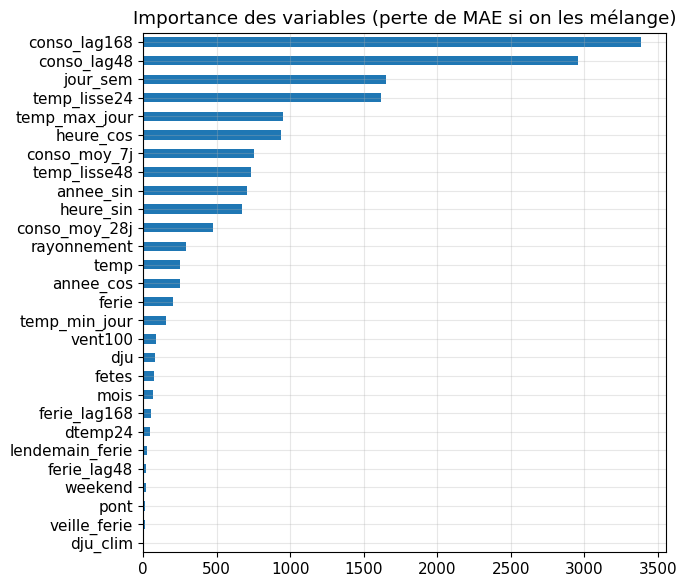

In [28]:

# %% 9. Pas journalier : SARIMAX (avec constante, info jusqu'à J-2) et Prophet
def jour_naif(s):
    out = s.resample("D").mean()
    out.index = out.index.tz_localize(None)
    return out


cmp = pd.DataFrame({
    "conso": jour_naif(y_te), "Naïve 168 h": jour_naif(te["conso_lag168"]),
    "RTE J-1": jour_naif(te["prev_j1"]), "RTE corrigé (biais glissant)": jour_naif(S0["rte_corr"]),
    "Ridge (mêmes variables)": jour_naif(p_ridge),
    "Modèle final": jour_naif(S0["p_te"]), "Modèle final corrigé (biais glissant)": jour_naif(S0["p_corr"]),
    "Modèle, météo bruitée (entraîné propre)": jour_naif(S1["p_te"]),
    "Modèle, météo bruitée (entraîné bruité)": jour_naif(S2["p_te"])})
assert len(cmp) == 366

jr = data.resample("D").agg({"conso": "mean", "temp": "mean", "ferie": "max", "pont": "max", "jour_sem": "first"})
jr.index = jr.index.tz_localize(None)
jr["dju"] = (15.5 - jr["temp"]).clip(lower=0)
jr["dju_clim"] = (jr["temp"] - 23).clip(lower=0)
jr["weekend"] = (jr["jour_sem"] >= 5).astype(int)
for k in (1, 2):
    jr[f"s{k}"] = np.sin(2 * np.pi * k * jr.index.dayofyear / 365.25)
    jr[f"c{k}"] = np.cos(2 * np.pi * k * jr.index.dayofyear / 365.25)
jr["const"] = 1.0                                   # la constante qui manquait dans la 1re version
exog = ["dju", "dju_clim", "ferie", "pont", "weekend", "s1", "c1", "s2", "c2", "const"]

try:
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    y_gw, X_all = jr["conso"] / 1000, jr[exog]
    res_s = SARIMAX(y_gw.loc[:"2023"], exog=X_all.loc[:"2023"], order=(1, 0, 0),
                    seasonal_order=(1, 0, 0, 7)).fit(disp=False, maxiter=300)
    print("SARIMAX :", res_s.params.round(3).to_dict())
    print("Convergence :", res_s.mle_retvals.get("converged"),
          "| le coefficient de dju n'est pas comparable à la pente de la question 1 (termes annuels présents)")
    pos = {dd: i for i, dd in enumerate(y_gw.index)}
    prev = {}
    for dd in cmp.index:                              # information jusqu'à J-2 seulement
        i = pos[dd]
        r = res_s.apply(y_gw.iloc[:i - 1], exog=X_all.iloc[:i - 1], refit=False)
        prev[dd] = r.forecast(steps=2, exog=X_all.iloc[i - 1:i + 1].to_numpy()).iloc[-1]
    cmp["SARIMAX (info jusqu'à J-2)"] = pd.Series(prev) * 1000
except Exception as e:
    print("SARIMAX ignoré :", e)

try:
    from prophet import Prophet
    p = Prophet(yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False)
    p.add_country_holidays(country_name="FR")
    for r_ in ["dju", "dju_clim"]:
        p.add_regressor(r_)
    nom_idx = jr.index.name or "index"
    fit_p = jr.loc[:"2023"].reset_index().rename(columns={nom_idx: "ds", "conso": "y"})
    p.fit(fit_p[["ds", "y", "dju", "dju_clim"]])
    fut = jr.loc["2024"].reset_index().rename(columns={nom_idx: "ds"})[["ds", "dju", "dju_clim"]]
    cmp["Prophet"] = p.predict(fut)["yhat"].values
except Exception as e:
    print("Prophet ignoré :", e)

# %% 10. Tableau final journalier (366 jours, mêmes conditions pour tous)
noms = [c for c in cmp.columns if c != "conso"]
final = rapport({n: cmp[n] for n in noms}, cmp["conso"], "RTE J-1", 7)
print("TEST 2024 - JOURNALIER")
display(final.round(3))
final.to_csv(DOSSIER / "q2_final_journalier.csv", encoding="utf-8-sig")

paires = [("Modèle final", "RTE J-1"), ("Modèle final corrigé (biais glissant)", "RTE corrigé (biais glissant)"),
          ("Modèle, météo bruitée (entraîné propre)", "RTE J-1"),
          ("Modèle, météo bruitée (entraîné bruité)", "RTE J-1"),
          ("SARIMAX (info jusqu'à J-2)", "RTE J-1"), ("Modèle final", "SARIMAX (info jusqu'à J-2)"),
          ("Prophet", "RTE J-1")]
tests_j = pd.DataFrame({f"{a} contre {b}": comparer(cmp["conso"], cmp[a], cmp[b], 7)
                        for a, b in paires if a in cmp.columns and b in cmp.columns}).T
print("Tests de Diebold-Mariano (journalier ; gain positif = premier modèle meilleur)")
display(tests_j.round(4))
tests_j.to_csv(DOSSIER / "q2_tests_journalier.csv", encoding="utf-8-sig")

# %% 11. Où le modèle se trompe-t-il ? (mois, température, pires jours, importance, graphiques)
err = pd.DataFrame({"modele": cmp["Modèle final"] - cmp["conso"], "rte": cmp["RTE J-1"] - cmp["conso"]})
pct = 100 * err.abs().div(cmp["conso"], axis=0)
print("MAPE journalier par mois (%) et biais par mois (MW), modèle sans correction")
display(pd.concat([pct.groupby(pct.index.month).mean().add_suffix("_MAPE"),
                   err.groupby(err.index.month).mean().add_suffix("_biais")], axis=1).round(2))

tranche = pd.cut(jr.loc["2024", "temp"].loc[cmp.index], [-10, 5, 10, 15, 20, 40])
print("MAPE journalier par tranche de température (%)")
display(pct.groupby(tranche, observed=True).mean().round(2))

print("Les 10 pires jours du modèle (sans correction)")
display(pd.DataFrame({"conso": cmp["conso"], "modele": cmp["Modèle final"], "rte": cmp["RTE J-1"],
                      "erreur_modele": err["modele"], "erreur_rte": err["rte"]})
        .loc[err["modele"].abs().sort_values(ascending=False).index[:10]].round(0))

echant = va.sample(min(3000, len(va)), random_state=SEED)
imp = permutation_importance(S0["modele"], echant[FEATS], echant["cible"], n_repeats=3,
                             random_state=SEED, scoring="neg_mean_absolute_error")
pd.Series(imp.importances_mean, index=FEATS).sort_values().plot(
    kind="barh", figsize=(7, 6), title="Importance des variables (perte de MAE si on les mélange)")
plt.tight_layout(); plt.show()



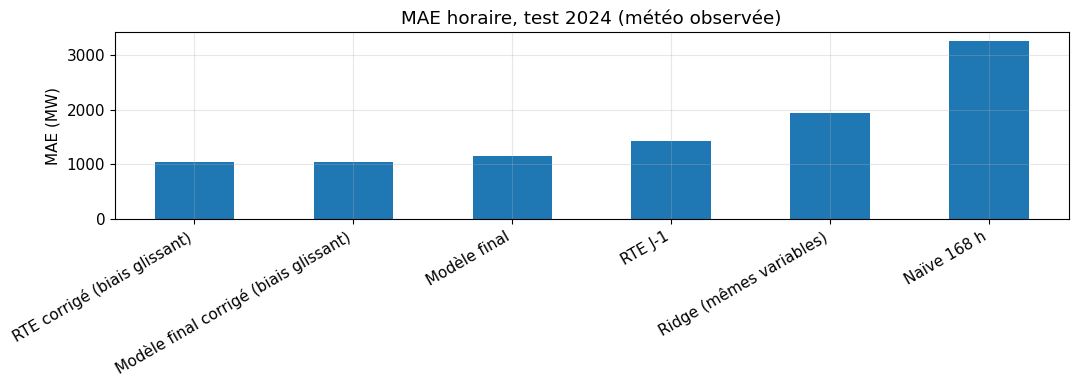

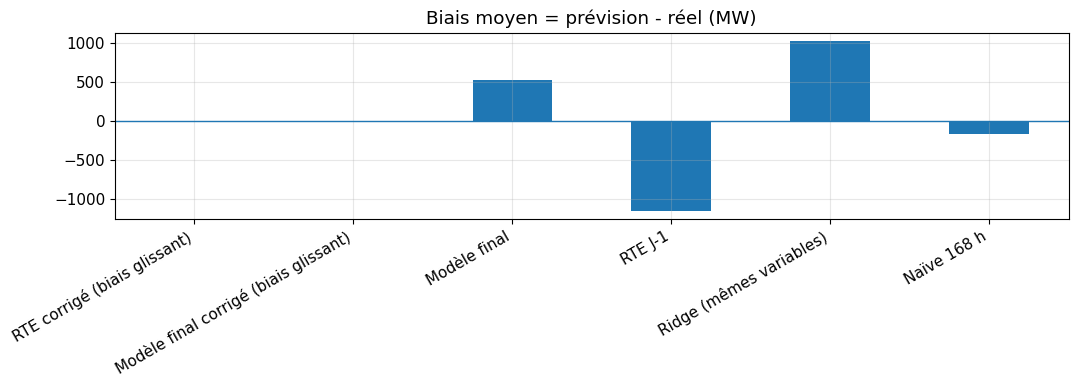

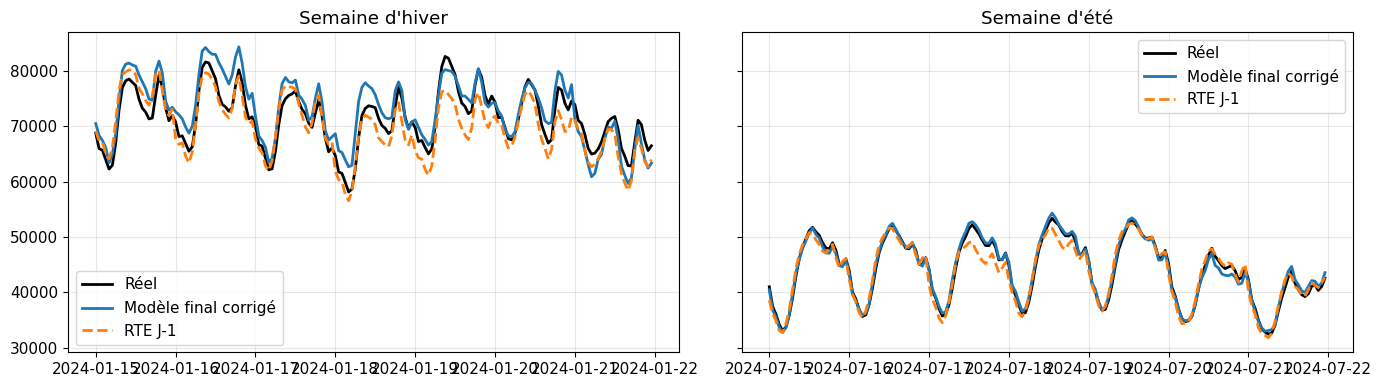

RÉSUMÉ
Jeu retenu            : F : E + férié sur les retards
Algorithme et réglage : XGB {'n_estimators': 600, 'learning_rate': 0.05, 'max_depth': 6, 'subsample': 0.8, 'colsample_bytree': 0.8} | poids >= 2018 : 3
Correction du biais   : météo parfaite -> 7 | bruitée -> 14
Entraînement sur météo bruitée retenu par la validation : True
Meilleur modèle HORAIRE (hors RTE corrigé) : Modèle final corrigé (biais glissant)

RAPPELS
- Écart vs RTE négatif = erreur plus faible que RTE. Biais positif = prévision trop haute.
- Les lignes 'corrigé' appliquent la même correction aux deux : c'est la comparaison à biais égal.
- 'RTE corrigé' n'est pas ce que RTE publie : c'est RTE auquel on applique notre correction.
- Météo observée = résultat rétrospectif ; la section météo bruitée dépend de SIGMA_METEO (hypothèse).
- 2024 n'est un vrai test que si tu ne modifies plus le protocole en regardant ces résultats.


In [29]:
horaire["MAE_MW"].sort_values().plot(kind="bar", figsize=(11, 4), title="MAE horaire, test 2024 (météo observée)")
plt.ylabel("MAE (MW)"); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()
horaire["Biais_MW"].plot(kind="bar", figsize=(11, 4), title="Biais moyen = prévision - réel (MW)")
plt.axhline(0, linewidth=1); plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for a, (deb, fin, titre) in zip(ax, [("2024-01-15", "2024-01-21", "Semaine d'hiver"),
                                      ("2024-07-15", "2024-07-21", "Semaine d'été")]):
    a.plot(y_te.loc[deb:fin], label="Réel", color="black")
    a.plot(S0["p_corr"].loc[deb:fin], label="Modèle final corrigé")
    a.plot(te["prev_j1"].loc[deb:fin], label="RTE J-1", ls="--")
    a.set_title(titre); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# %% 12. Résumé et rappels d'interprétation
print("RÉSUMÉ")
print("Jeu retenu            :", meilleur_jeu)
print("Algorithme et réglage :", ALGO, PARAMS, "| poids >= 2018 :", POIDS)
print("Correction du biais   : météo parfaite ->", S0["fenetre"] or "aucune",
      "| bruitée ->", S1["fenetre"] or "aucune")
print("Entraînement sur météo bruitée retenu par la validation :", ADOPTER_BRUIT)
print("Meilleur modèle HORAIRE (hors RTE corrigé) :",
      horaire.drop(index=[i for i in horaire.index if i.startswith("RTE")]).index[0])
print("\nRAPPELS")
print("- Écart vs RTE négatif = erreur plus faible que RTE. Biais positif = prévision trop haute.")
print("- Les lignes 'corrigé' appliquent la même correction aux deux : c'est la comparaison à biais égal.")
print("- 'RTE corrigé' n'est pas ce que RTE publie : c'est RTE auquel on applique notre correction.")
print("- Météo observée = résultat rétrospectif ; la section météo bruitée dépend de SIGMA_METEO (hypothèse).")
print("- 2024 n'est un vrai test que si tu ne modifies plus le protocole en regardant ces résultats.")

MAE horaire par année (MW) - années normales : [2016, 2017, 2018, 2019]


modele,Modèle (avec retards),Modèle sans retards,RTE J-1,Naïve 168 h
annee,,,,
2016,1013.0,979.0,845.0,3410.0
2017,961.0,1048.0,848.0,3588.0
2018,905.0,1046.0,880.0,4102.0
2019,882.0,1072.0,831.0,3329.0
2020,1597.0,2683.0,845.0,3168.0
2021,1084.0,1377.0,914.0,4004.0
2022,1244.0,2233.0,1018.0,3496.0
2023,1481.0,3398.0,1342.0,3466.0
2024,1152.0,2604.0,1428.0,3246.0


MAPE (%)


modele,Modèle (avec retards),Modèle sans retards,RTE J-1,Naïve 168 h
annee,,,,
2016,1.85,1.77,1.55,6.00
2017,1.75,1.90,1.54,6.26
2018,1.67,1.95,1.62,7.04
2019,1.65,2.00,1.54,6.02
2020,3.32,5.67,1.69,6.04
2021,2.02,2.59,1.71,7.10
2022,2.40,4.43,1.98,6.50
2023,2.87,6.66,2.73,6.52
2024,2.26,5.06,2.86,6.08


Indice de la MAE (100 = moyenne des années normales)


...

,MAE modèle / MAE RTE
annee,
2016,1.20
2017,1.13
2018,1.03
2019,1.06
2020,1.89
2021,1.19
2022,1.22
2023,1.10
2024,0.81


MAPE mensuelle (%) - Modèle (avec retards)


annee,2016,2017,2018,2019,2020,2021,2022,2023,2024
mois,,,,,,,,,
1,2.04,2.32,1.25,1.30,1.51,1.94,1.66,3.35,3.40
2,1.91,1.58,1.84,1.53,1.47,2.53,1.95,5.25,2.37
3,1.63,2.25,1.65,2.28,6.33,3.09,2.27,4.12,2.74
4,1.96,2.14,2.51,2.03,7.70,3.34,2.67,3.01,2.85
5,3.04,2.01,2.08,2.04,5.81,2.72,1.63,2.45,2.53
6,1.56,1.76,1.07,1.41,3.26,1.63,1.72,1.59,1.39
7,1.62,1.33,1.18,1.33,1.30,0.79,1.61,1.56,1.32
8,1.31,1.39,1.91,1.27,2.65,1.61,1.69,3.05,2.03
9,1.24,1.23,0.86,1.39,1.90,0.97,1.87,1.94,1.67


MAPE mensuelle (%) - RTE J-1


annee,2016,2017,2018,2019,2020,2021,2022,2023,2024
mois,,,,,,,,,
1,1.70,1.67,1.87,1.50,1.31,1.58,1.74,1.79,3.01
2,1.84,1.58,1.53,1.52,1.74,1.77,2.01,2.50,2.90
3,1.46,1.79,1.71,1.64,2.79,1.72,2.56,3.52,2.58
4,1.59,1.50,2.05,1.41,1.85,1.70,3.11,3.91,3.32
5,1.64,1.40,1.83,1.55,1.65,2.28,1.54,3.27,3.95
6,1.60,1.57,1.46,1.41,1.55,1.30,1.79,2.29,3.07
7,1.52,1.52,1.42,1.50,1.47,1.51,1.59,2.43,2.85
8,1.50,1.49,1.54,1.49,1.75,1.87,1.89,2.72,2.19
9,1.32,1.15,1.28,1.39,1.53,1.25,1.40,1.70,2.86


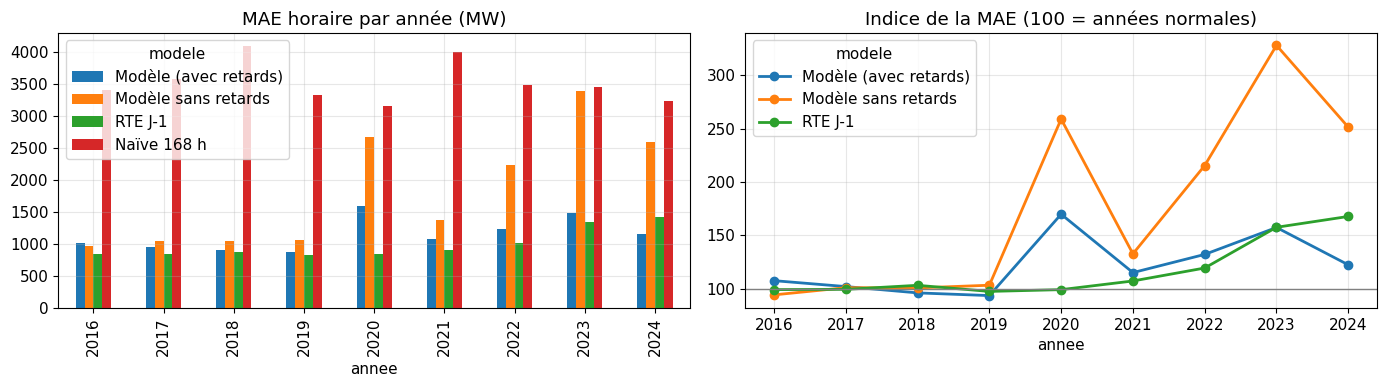

Écart moyen annuel à la consommation attendue (%) : 2016-2019 = placebos, 2020-2024 = après la rupture


,écart %
datetime,
2016,-0.11
2017,-0.14
2018,-0.55
2019,-1.08
2020,-4.99
2021,-2.53
2022,-4.60
2023,-7.52
2024,-6.55


EFFET PAR PÉRIODE (consommation réelle contre consommation attendue d'après 2012-2019)
Effet négatif = consommation plus basse que prévu. L'IC ne couvre que l'incertitude statistique de la moyenne.


,jours,écart %,IC95 bas,IC95 haut,placebo moyen %,placebo min,placebo max,nb placebos,effet % (écart - placebo),effet MW
période,,,,,,,,,,
Confinement 1 (17 mars - 10 mai 2020),55,-13.59,-14.62,-12.57,-1.03,-1.82,0.11,4,-12.56,-5524.71
Entre les deux confinements (11 mai - 29 oct. 2020),172,-4.06,-5.21,-2.92,-0.60,-1.23,-0.15,4,-3.46,-1537.91
Confinement 2 (30 oct. - 14 déc. 2020),46,-4.46,-5.43,-3.49,-0.04,-1.26,0.64,4,-4.42,-2580.65
Année 2020,366,-4.99,-6.22,-3.75,-0.47,-1.08,-0.11,4,-4.52,-2296.22
Année 2021,365,-2.53,-2.96,-2.09,-0.47,-1.08,-0.11,4,-2.06,-1099.55
Année 2022,365,-4.60,-5.56,-3.63,-0.47,-1.08,-0.11,4,-4.13,-2121.27
Hiver de sobriété (oct. 2022 - mars 2023),182,-9.28,-9.97,-8.59,-0.04,-0.80,0.38,3,-9.24,-5150.55
Année 2023,365,-7.52,-8.08,-6.97,-0.47,-1.08,-0.11,4,-7.05,-3507.69
Année 2024,366,-6.55,-7.17,-5.92,-0.47,-1.08,-0.11,4,-6.08,-3044.29


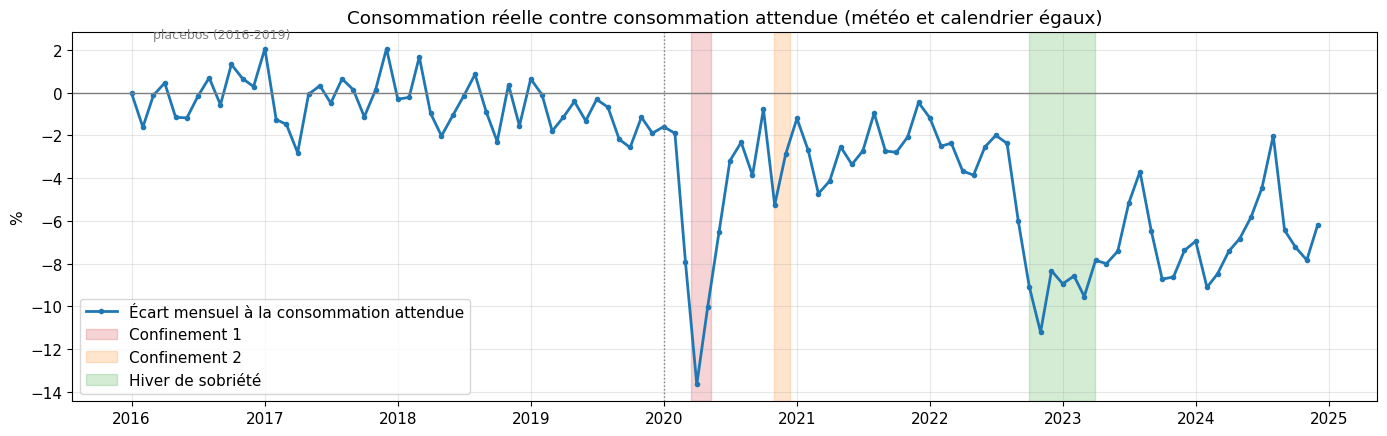

Écart journalier sur 2016-2019 (placebos) : moyenne -0.47 %, écart-type 2.02 %
Écart-type des écarts mensuels des placebos : 1.15 %
=> un effet n'est lisible que s'il dépasse nettement ces ordres de grandeur.
RÉSUMÉ
Années normales du backtest : [2016, 2017, 2018, 2019]
  2020 : indice MAE modèle 170, RTE 99 | rapport modèle/RTE 1.89
  2021 : indice MAE modèle 115, RTE 107 | rapport modèle/RTE 1.19
  2022 : indice MAE modèle 132, RTE 120 | rapport modèle/RTE 1.22
  2023 : indice MAE modèle 158, RTE 158 | rapport modèle/RTE 1.10
  2024 : indice MAE modèle 123, RTE 168 | rapport modèle/RTE 0.81
RAPPELS
- Backtest : un modèle réentraîné chaque année s'adapte aux nouveaux niveaux grâce aux retards ;
  le modèle sans retards, lui, montre l'écart brut (son biais mesure le changement de niveau).
- Les premières années du backtest ont moins de données d'entraînement : comparer au témoin RTE.
- Contrefactuel : écart à un comportement passé, pas un effet causal.
- La météo est observée : l'écart

In [30]:
# =============================================================================
# QUESTION 3 - Les prévisions résistent-elles aux ruptures (Covid 2020, sobriété 2022-2023) ?
#
# Deux sous-questions distinctes :
#   (a) PRÉVISION : de combien l'erreur du modèle (et celle de RTE) augmente-t-elle en 2020,
#       2021, 2022, 2023 par rapport à des années "normales" (2016-2019) ?  -> backtest annuel
#   (b) EFFET : de combien la consommation s'est-elle écartée de ce que la météo et le calendrier
#       laissaient attendre ?  -> contrefactuel entraîné AVANT la rupture, calibré par des "placebos"
#
# PRÉREQUIS : avoir lancé les cellules 0 à 4 de question2_version_finale.py
#   (objets utilisés : data, d, FEATS, ALGO, PARAMS, POIDS, JEUX, evaluer, ajuster_predire).
#
# LIMITE IMPORTANTE : (b) mesure un ÉCART à un comportement passé, pas une cause. Un écart en 2022-2023
#   mélange sobriété, prix, après-Covid (télétravail), efficacité énergétique, industrie, autoconsommation.
# =============================================================================

# %% 0. Prérequis et réglages
import numpy as np, pandas as pd, matplotlib.pyplot as plt, statsmodels.api as sm
from pathlib import Path

for nom in ["data", "d", "FEATS", "ALGO", "PARAMS", "POIDS", "JEUX", "evaluer", "ajuster_predire"]:
    assert nom in globals(), f"Lance d'abord les cellules 0 à 4 de question2_version_finale.py ({nom} manquant)"
try:
    display
except NameError:
    display = print
try:
    DOSSIER = Path(DOSSIER)
except NameError:
    DOSSIER = Path(".")

RAPIDE_Q3 = False        # True : version réduite pour vérifier que le code tourne
FEATS_C = JEUX["C : calendrier + météo (sans retards)"]       # sans mémoire de la consommation
ANNEES_BACKTEST = [2018, 2019, 2020, 2021, 2022, 2023, 2024] if RAPIDE_Q3 else list(range(2016, 2025))
ANNEES_NORMALES = [2018, 2019] if RAPIDE_Q3 else [2016, 2017, 2018, 2019]
ANNEES_PLACEBO = (2016, 2017, 2018, 2019)


def jour_naif(s):
    out = s.resample("D").mean()
    out.index = out.index.tz_localize(None)
    return out


# %% 1. (a) Backtest annuel : on réentraîne chaque année sur tout le passé et on prévoit l'année
# Deux modèles : F (avec retards de consommation) et C (sans retards, donc sans mémoire du niveau).
# RTE sert de témoin : si une rupture dégrade aussi RTE, elle touche tout le monde.
preds, lignes = {}, []
for an in ANNEES_BACKTEST:
    train, test = d[d.index.year < an], d[d.index.year == an]
    p_f, _ = ajuster_predire(ALGO, PARAMS, POIDS, FEATS, train, test)
    p_c, _ = ajuster_predire(ALGO, PARAMS, POIDS, FEATS_C, train, test)
    preds[an] = pd.DataFrame({"reel": test["cible"], "Modèle (avec retards)": p_f,
                              "Modèle sans retards": p_c, "RTE J-1": test["prev_j1"],
                              "Naïve 168 h": test["conso_lag168"]})
    for nom in preds[an].columns[1:]:
        lignes.append({"annee": an, "modele": nom, **evaluer(test["cible"], preds[an][nom])})
bt = pd.DataFrame(lignes)

ordre = ["Modèle (avec retards)", "Modèle sans retards", "RTE J-1", "Naïve 168 h"]
mae = bt.pivot(index="annee", columns="modele", values="MAE_MW")[ordre]
biais = bt.pivot(index="annee", columns="modele", values="Biais_MW")[ordre]
mape = bt.pivot(index="annee", columns="modele", values="MAPE_%")[ordre]
indice = 100 * mae / mae.loc[ANNEES_NORMALES].mean()           # 100 = moyenne des années normales

print(f"MAE horaire par année (MW) - années normales : {ANNEES_NORMALES}")
display(mae.round(0))
print("MAPE (%)")
display(mape.round(2))
print("Indice de la MAE (100 = moyenne des années normales)")
display(indice.round(0))
print("Biais moyen (MW) = prévision - réel")
display(biais.round(0))
rapport_rte = (mae["Modèle (avec retards)"] / mae["RTE J-1"]).rename("MAE modèle / MAE RTE")
print("Le modèle se dégrade-t-il plus que RTE ? (rapport des MAE, <1 = modèle meilleur)")
display(rapport_rte.round(2).to_frame())
bt.to_csv(DOSSIER / "q3_backtest_annuel.csv", index=False, encoding="utf-8-sig")

# MAPE mensuelle : une rupture de deux mois est diluée dans une moyenne annuelle
tous = pd.concat(preds.values())
tous["annee"], tous["mois"] = tous.index.year, tous.index.month
for nom in ["Modèle (avec retards)", "RTE J-1"]:
    e = 100 * (tous[nom] - tous["reel"]).abs() / tous["reel"]
    print(f"MAPE mensuelle (%) - {nom}")
    display(e.groupby([tous["mois"], tous["annee"]]).mean().unstack().round(2))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
mae.plot(kind="bar", ax=ax[0], title="MAE horaire par année (MW)")
indice[["Modèle (avec retards)", "Modèle sans retards", "RTE J-1"]].plot(
    marker="o", ax=ax[1], title="Indice de la MAE (100 = années normales)")
ax[1].axhline(100, color="gray", lw=1)
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# %% 2. (b) Contrefactuel : consommation attendue d'après le comportement d'avant la rupture
# Modèle SANS retards (météo + calendrier uniquement), poids égaux, entraîné avant la période étudiée.
#  - 2020-2024 : un seul modèle entraîné sur 2012-2019 (comportement "d'avant").
#  - 2016-2019 : "placebos" : chaque année est prédite par un modèle entraîné sur les années précédentes.
#    Ils mesurent l'écart NORMAL (dérive de fond, erreur du modèle) sur une période sans rupture.
def contrefactuel(annee_max_train, annees_test):
    train = d[d.index.year <= annee_max_train]
    test = d[d.index.year.isin(annees_test)]
    p, _ = ajuster_predire(ALGO, PARAMS, 1, FEATS_C, train, test)
    return p


cf = pd.concat([contrefactuel(py - 1, [py]) for py in ANNEES_PLACEBO]
               + [contrefactuel(2019, [2020, 2021, 2022, 2023, 2024])])
reel_j = jour_naif(d.loc[cf.index, "cible"])
cf_j = jour_naif(cf)
res_j = 100 * (reel_j / cf_j - 1)                    # écart journalier, en % de la consommation attendue

print("Écart moyen annuel à la consommation attendue (%) : 2016-2019 = placebos, 2020-2024 = après la rupture")
res_an = res_j.groupby(res_j.index.year).mean().rename("écart %")
display(res_an.round(2).to_frame())

# %% 3. Effet par période, avec incertitude et comparaison aux placebos
FENETRES = {
    "Confinement 1 (17 mars - 10 mai 2020)": ("2020-03-17", "2020-05-10"),
    "Entre les deux confinements (11 mai - 29 oct. 2020)": ("2020-05-11", "2020-10-29"),
    "Confinement 2 (30 oct. - 14 déc. 2020)": ("2020-10-30", "2020-12-14"),
    "Année 2020": ("2020-01-01", "2020-12-31"),
    "Année 2021": ("2021-01-01", "2021-12-31"),
    "Année 2022": ("2022-01-01", "2022-12-31"),
    "Hiver de sobriété (oct. 2022 - mars 2023)": ("2022-10-01", "2023-03-31"),
    "Année 2023": ("2023-01-01", "2023-12-31"),
    "Année 2024": ("2024-01-01", "2024-12-31"),
}


def moyenne_hac(s):
    """Moyenne et intervalle à 95 % (jours voisins corrélés : écart-type HAC)."""
    r = sm.OLS(s.values, np.ones(len(s))).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
    lo, hi = r.conf_int()[0]
    return float(r.params[0]), float(lo), float(hi)


def fenetres_placebo(a, b):
    """Mêmes dates calendaires dans les années placebo 2016-2019 (fenêtre entièrement dans cette plage)."""
    a, b, out = pd.Timestamp(a), pd.Timestamp(b), []
    for py in ANNEES_PLACEBO:
        k = a.year - py
        a2, b2 = a - pd.DateOffset(years=k), b - pd.DateOffset(years=k)
        if a2.year >= ANNEES_PLACEBO[0] and b2.year <= ANNEES_PLACEBO[-1]:
            out.append((a2, b2))
    return out


lignes = []
for nom, (a, b) in FENETRES.items():
    s = res_j.loc[a:b].dropna()
    m, lo, hi = moyenne_hac(s)
    pl = [res_j.loc[a2:b2].mean() for a2, b2 in fenetres_placebo(a, b)]
    pm = float(np.mean(pl)) if pl else np.nan
    effet = m - pm if pl else np.nan
    lignes.append({"période": nom, "jours": len(s), "écart %": m, "IC95 bas": lo, "IC95 haut": hi,
                   "placebo moyen %": pm, "placebo min": min(pl) if pl else np.nan,
                   "placebo max": max(pl) if pl else np.nan, "nb placebos": len(pl),
                   "effet % (écart - placebo)": effet,
                   "effet MW": effet / 100 * reel_j.loc[a:b].mean() if pl else np.nan})
effets = pd.DataFrame(lignes).set_index("période")
print("EFFET PAR PÉRIODE (consommation réelle contre consommation attendue d'après 2012-2019)")
print("Effet négatif = consommation plus basse que prévu. L'IC ne couvre que l'incertitude statistique de la moyenne.")
display(effets.round(2))
effets.to_csv(DOSSIER / "q3_effets_par_periode.csv", encoding="utf-8-sig")

# %% 4. Trajectoire mensuelle de l'écart (2016-2024)
res_m = res_j.resample("MS").mean()
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(res_m.index, res_m.values, marker="o", ms=3, color="tab:blue", label="Écart mensuel à la consommation attendue")
ax.axhline(0, color="gray", lw=1)
ax.axvline(pd.Timestamp("2020-01-01"), color="gray", ls=":", lw=1)
ax.text(pd.Timestamp("2016-03-01"), ax.get_ylim()[1] * 0.9, "placebos (2016-2019)", fontsize=9, color="gray")
for (a, b), c, lab in [(FENETRES["Confinement 1 (17 mars - 10 mai 2020)"], "tab:red", "Confinement 1"),
                       (FENETRES["Confinement 2 (30 oct. - 14 déc. 2020)"], "tab:orange", "Confinement 2"),
                       (FENETRES["Hiver de sobriété (oct. 2022 - mars 2023)"], "tab:green", "Hiver de sobriété")]:
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=c, alpha=0.2, label=lab)
ax.set_ylabel("%"); ax.set_title("Consommation réelle contre consommation attendue (météo et calendrier égaux)")
ax.legend(loc="lower left"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

# %% 5. Les écarts sont-ils plus grands que le bruit habituel ? (contrôle de lecture)
bruit_placebo = res_j.loc["2016-01-01":"2019-12-31"]
print(f"Écart journalier sur 2016-2019 (placebos) : moyenne {bruit_placebo.mean():.2f} %, "
      f"écart-type {bruit_placebo.std():.2f} %")
print("Écart-type des écarts mensuels des placebos :",
      round(res_m.loc["2016-01-01":"2019-12-31"].std(), 2), "%")
print("=> un effet n'est lisible que s'il dépasse nettement ces ordres de grandeur.")

# %% 6. Résumé et rappels
print("RÉSUMÉ")
print(f"Années normales du backtest : {ANNEES_NORMALES}")
for an in [2020, 2021, 2022, 2023, 2024]:
    if an in indice.index:
        print(f"  {an} : indice MAE modèle {indice.loc[an, 'Modèle (avec retards)']:.0f}, "
              f"RTE {indice.loc[an, 'RTE J-1']:.0f} | rapport modèle/RTE {rapport_rte.loc[an]:.2f}")
print("RAPPELS")
print("- Backtest : un modèle réentraîné chaque année s'adapte aux nouveaux niveaux grâce aux retards ;")
print("  le modèle sans retards, lui, montre l'écart brut (son biais mesure le changement de niveau).")
print("- Les premières années du backtest ont moins de données d'entraînement : comparer au témoin RTE.")
print("- Contrefactuel : écart à un comportement passé, pas un effet causal.")
print("- La météo est observée : l'écart est mesuré 'à météo égale', sans erreur de prévision météo.")

Entraînement : 104,473 observations
Test 2024    : 8,784 observations

PERFORMANCES SUR LE TEST 2024
                                     Nb variables     n    MAE_MW   RMSE_MW  MAPE_%  Biais_MW  Ecart_type_MW
Configuration                                                                                               
A - Calendrier seul                            12  8784  4213.848  5792.467   8.159  3260.686       4787.818
B - Calendrier + historique                    18  8784  2069.263  2986.456   3.939   536.131       2938.106
C - Calendrier + météo                         22  8784  2604.489  3095.483   5.060  2475.656       1858.369
D - Calendrier + historique + météo            28  8784  1153.642  1550.086   2.263   516.803       1461.480

GAINS PAR RAPPORT AU CALENDRIER SEUL
                                     Gain MAE (MW)  Gain MAE (%)  Gain RMSE (MW)  Gain RMSE (%)
Configuration                                                                                  
A - Calendrier 

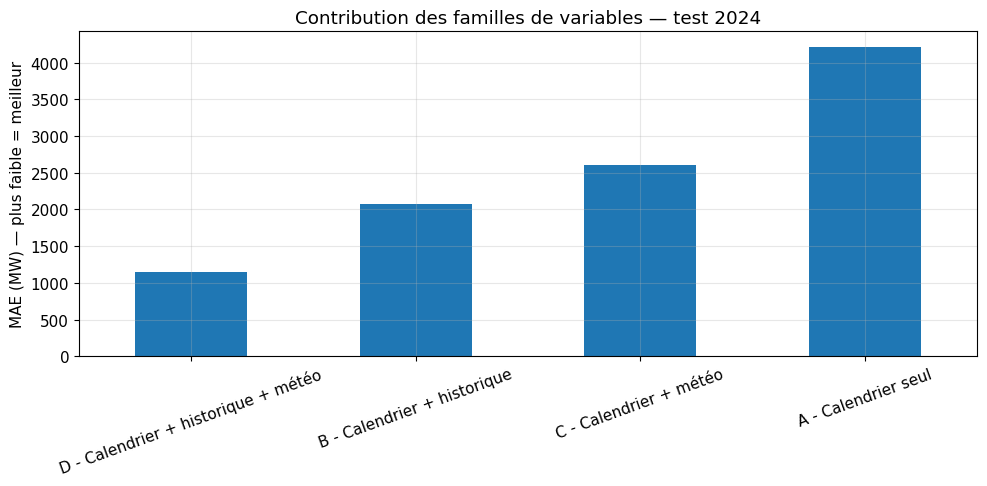


Fichiers créés : q4_performances.csv et q4_gains_vs_calendrier.csv


In [31]:

# =============================================================================
# QUESTION 4 — Quel gain prédictif apporte chaque famille de variables ?
# Calendrier / historique de consommation / météo
#
# PRÉREQUIS : avoir exécuté les cellules de la question 2.
# Le modèle, ses paramètres et les poids sont ceux sélectionnés en Q2.
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# %% 1. Définition des familles de variables
cal = [
    "heure_sin", "heure_cos", "annee_sin", "annee_cos",
    "jour_sem", "mois", "ferie", "pont", "weekend"
]

cal2 = ["veille_ferie", "lendemain_ferie", "fetes"]

lags = [
    "conso_lag48", "conso_lag168",
    "conso_moy_7j", "conso_moy_28j"
]

met = ["temp", "temp_lisse24", "temp_lisse48", "dju", "dju_clim"]

met2 = [
    "temp_min_jour", "temp_max_jour",
    "dtemp24", "vent100", "rayonnement"
]

# Toutes les variables de calendrier
F_CAL = cal + cal2

# Historique de consommation
F_HIST = lags + ["ferie_lag48", "ferie_lag168"]

# Météo
F_METEO = met + met2

# Quatre configurations comparables
CONFIGS = {
    "A - Calendrier seul": F_CAL,
    "B - Calendrier + historique": F_CAL + F_HIST,
    "C - Calendrier + météo": F_CAL + F_METEO,
    "D - Calendrier + historique + météo": F_CAL + F_HIST + F_METEO,
}

# Vérifier la présence des variables
for nom, features in CONFIGS.items():
    manquantes = [f for f in features if f not in d.columns]
    if manquantes:
        raise ValueError(f"{nom} : variables manquantes : {manquantes}")

# %% 2. Découpage temporel : entraînement jusqu'en 2023, test en 2024
# d a déjà été construit dans la question 2 avec les mêmes lignes
# disponibles pour les variables des différents jeux.
train = d[d.index.year <= 2023].copy()
test = d[d.index.year == 2024].copy()

print(f"Entraînement : {len(train):,} observations")
print(f"Test 2024    : {len(test):,} observations")

if train.empty or test.empty:
    raise ValueError("Vérifie que d contient bien les années jusqu'à 2024.")

# %% 3. Entraîner et évaluer chaque configuration
resultats = []
predictions = {}

for nom, features in CONFIGS.items():
    pred, modele = ajuster_predire(
        ALGO, PARAMS, POIDS, features, train, test
    )

    predictions[nom] = pred
    scores = evaluer(test["cible"], pred)

    resultats.append({
        "Configuration": nom,
        "Nb variables": len(features),
        **scores
    })

resultats = pd.DataFrame(resultats).set_index("Configuration")

print("\nPERFORMANCES SUR LE TEST 2024")
print(resultats.round(3).to_string())

# %% 4. Gains par rapport au calendrier seul
# Gain positif = amélioration ; gain négatif = dégradation.
reference = resultats.loc["A - Calendrier seul"]

gains = pd.DataFrame(index=resultats.index)
gains["Gain MAE (MW)"] = reference["MAE_MW"] - resultats["MAE_MW"]
gains["Gain MAE (%)"] = (
    100 * gains["Gain MAE (MW)"] / reference["MAE_MW"]
)
gains["Gain RMSE (MW)"] = reference["RMSE_MW"] - resultats["RMSE_MW"]
gains["Gain RMSE (%)"] = (
    100 * gains["Gain RMSE (MW)"] / reference["RMSE_MW"]
)

print("\nGAINS PAR RAPPORT AU CALENDRIER SEUL")
print(gains.round(2).to_string())

# %% 5. Comparaison graphique de la MAE
ax = resultats["MAE_MW"].sort_values().plot(
    kind="bar", figsize=(10, 5), rot=20
)
ax.set_title("Contribution des familles de variables — test 2024")
ax.set_ylabel("MAE (MW) — plus faible = meilleur")
ax.set_xlabel("")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# %% 6. Sauvegarde des résultats
resultats.to_csv("q4_performances.csv", encoding="utf-8-sig")
gains.to_csv("q4_gains_vs_calendrier.csv", encoding="utf-8-sig")

print("\nFichiers créés : q4_performances.csv et q4_gains_vs_calendrier.csv")



DEMANDE RÉSIDUELLE PAR HEURE (MW)
       moyenne  mediane  ecart_type
heure                              
0      49396.8  46375.0     10185.1
1      45732.7  42277.0     10355.9
2      44749.2  41110.5     10562.5
3      42469.1  38763.5     10443.1
4      41128.6  37486.0     10295.9
5      41797.9  38209.0     10541.1
6      44571.1  41152.5     11515.1
7      48377.1  45530.0     12977.5
8      50822.9  48341.0     13377.8
9      51890.5  49819.0     12999.5
10     51754.8  50015.5     12650.8
11     51193.1  49737.5     12435.5
12     51204.6  49831.0     12115.4
13     50472.6  49112.0     11911.7
14     48804.1  47843.5     11957.2
15     47476.5  46585.5     11715.0
16     46857.5  45744.5     11799.5
17     47479.5  45677.0     12228.5
18     50145.3  47200.5     13022.8
19     53154.6  49625.5     12963.9
20     52339.5  49058.5     11657.4
21     50154.6  47196.5     10496.5
22     49051.5  46132.5      9779.6
23     51110.3  48398.5      9926.6


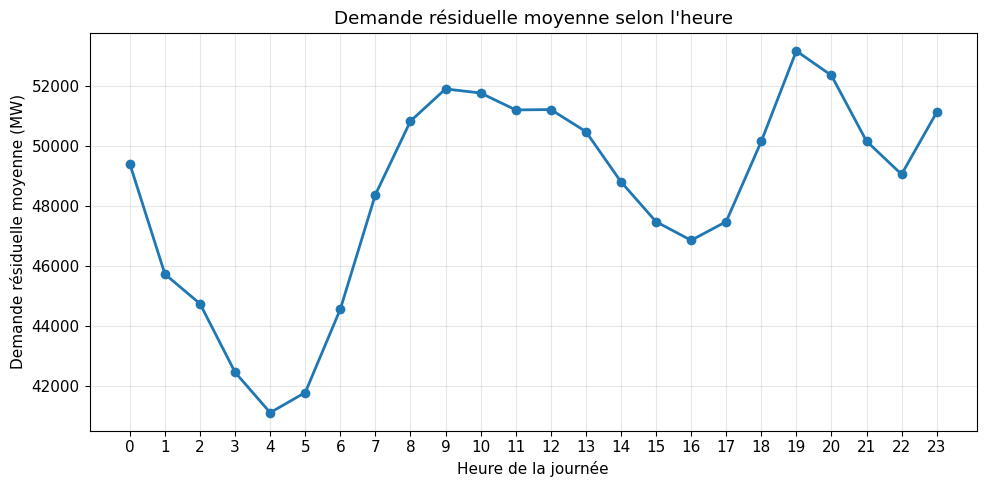


PROFIL HORAIRE PAR SAISON (MW)
saison    Hiver  Printemps      Été  Automne
heure                                       
0       60945.6    48972.8  41723.9  46121.9
1       57702.0    45436.6  37608.8  42367.1
2       57065.2    44513.6  36369.9  41272.1
3       54658.9    42223.6  34156.4  39024.5
4       53060.5    40826.6  33026.7  37783.7
5       53832.0    41526.7  33470.0  38548.8
6       57267.6    44396.9  35032.4  41790.9
7       62010.0    47872.3  37476.1  46379.2
8       64772.9    50051.6  40082.5  48617.1
9       65536.1    50835.0  41784.5  49632.8
10      65263.6    50138.1  42318.6  49523.0
11      64504.4    49130.6  42389.6  48968.5
12      64201.8    48978.2  42893.5  48959.7
13      63127.1    48174.0  42593.8  48203.7
14      61226.3    46188.8  41359.1  46647.3
15      59799.1    44460.3  40320.4  45531.9
16      59577.1    43422.2  39508.1  45137.7
17      61275.6    43429.7  39383.3  46067.7
18      65433.9    45625.7  40669.6  49122.2
19      68235.6    4967

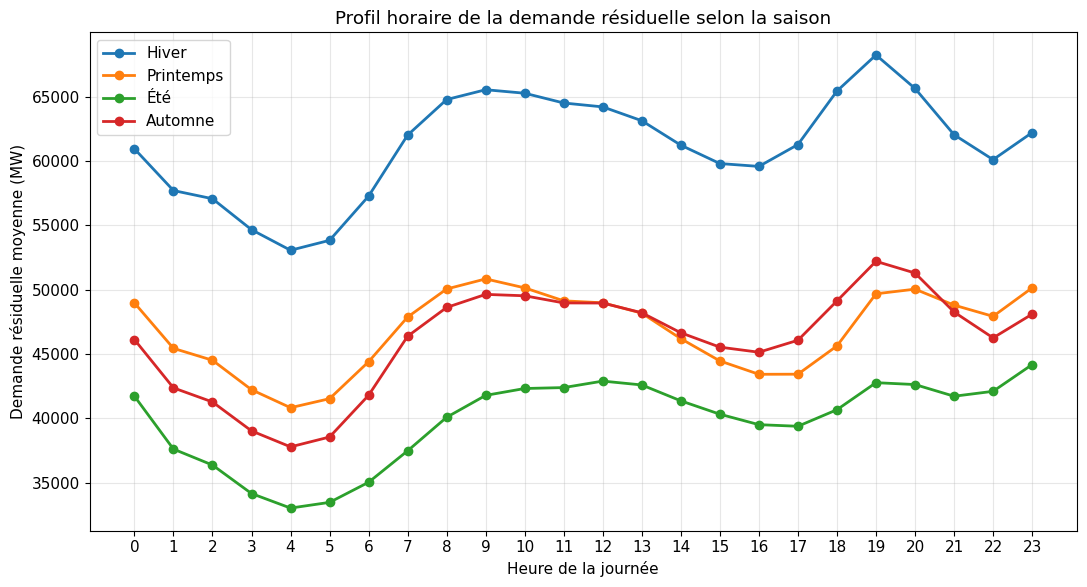

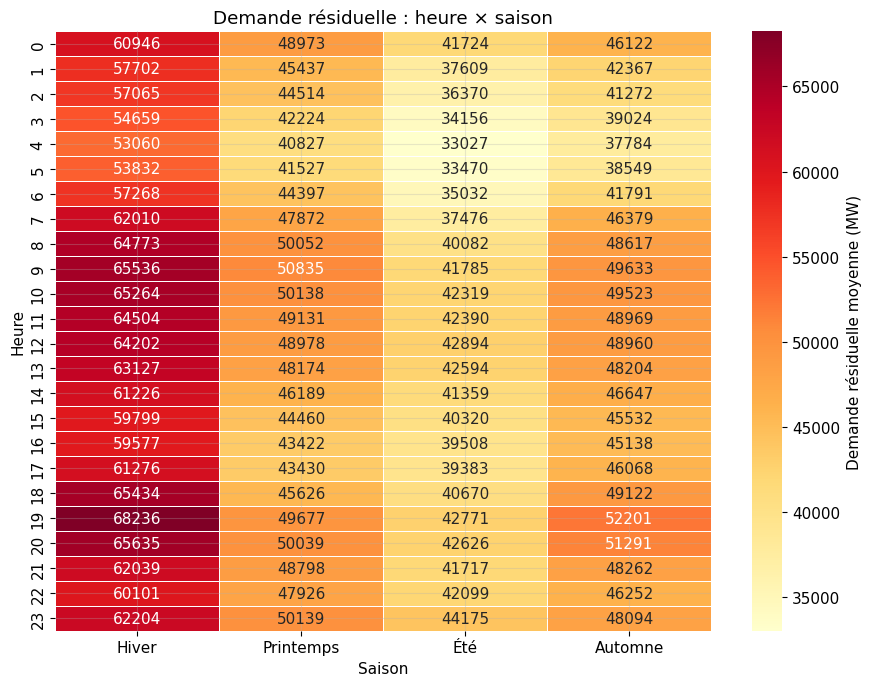


DEMANDE RÉSIDUELLE PAR MOIS (MW)
      moyenne  mediane  maximum
Jan   63810.0  64398.2  91390.5
Fév   61114.5  60716.8  99902.5
Mar   53418.5  53741.0  82493.5
Avr   46069.7  46277.8  73199.5
Mai   40848.6  40479.8  59981.0
Juin  40532.3  40425.2  54822.5
Juil  40811.3  40614.0  54887.0
Août  38124.0  38207.0  52020.5
Sep   40831.5  40884.0  54763.0
Oct   44103.2  44076.5  70139.5
Nov   53352.2  53426.2  83793.0
Déc   58750.0  59207.5  88141.5


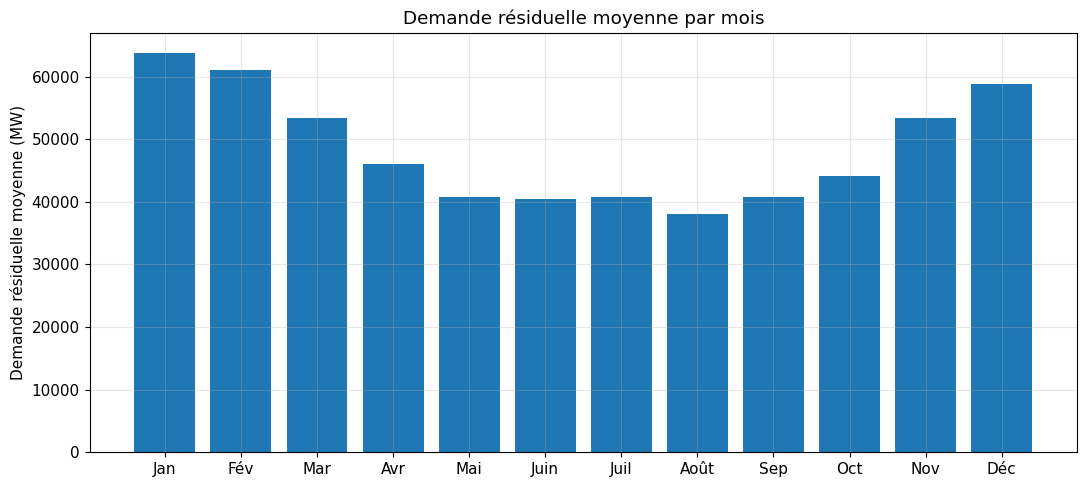


Heure où la demande résiduelle moyenne est la plus élevée : 19 h (53154.6 MW)
Combinaison saison-heure la plus élevée en moyenne : Hiver à 19 h (68235.6 MW)

Top 10 des heures-saisons par demande résiduelle moyenne :
saison  heure
Hiver   19       68235.6
        20       65635.5
        9        65536.1
        18       65433.9
        10       65263.6
        8        64772.9
        11       64504.4
        12       64201.8
        13       63127.1
        23       62204.4
Name: demande_residuelle, dtype: float64

Tableaux exportés : fichiers q5_*.csv


In [34]:
df = base.copy()

# Adapter les noms si nécessaire
correspondances = {
    "conso": ["conso", "Consommation (MW)"],
    "eolien": ["eolien", "Eolien (MW)", "Éolien (MW)"],
    "solaire": ["solaire", "Solaire (MW)"],
}

colonnes = {}
for cible, choix in correspondances.items():
    trouvee = next((c for c in choix if c in df.columns), None)
    if trouvee is None:
        raise ValueError(
            f"Colonne introuvable pour {cible}. "
            f"Colonnes disponibles : {list(df.columns)}"
        )
    colonnes[cible] = trouvee

df = df.rename(columns={
    colonnes["conso"]: "conso",
    colonnes["eolien"]: "eolien",
    colonnes["solaire"]: "solaire",
})

# Vérifier l'index temporel
if not isinstance(df.index, pd.DatetimeIndex):
    if "datetime" in df.columns:
        df = df.set_index("datetime")
    else:
        raise ValueError(
            "L'index doit être de type DatetimeIndex, "
            "ou une colonne 'datetime' doit exister."
        )

df = df.sort_index()

# Convertir les variables en numérique
for c in ["conso", "eolien", "solaire"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

# Demande résiduelle
df["demande_residuelle"] = (
    df["conso"] - df["eolien"] - df["solaire"]
)

# Retirer les observations incomplètes
df = df.dropna(subset=[
    "conso", "eolien", "solaire", "demande_residuelle"
])

# %% 2. Variables calendaires
df["heure"] = df.index.hour
df["mois"] = df.index.month
df["annee"] = df.index.year

saisons = {
    12: "Hiver", 1: "Hiver", 2: "Hiver",
    3: "Printemps", 4: "Printemps", 5: "Printemps",
    6: "Été", 7: "Été", 8: "Été",
    9: "Automne", 10: "Automne", 11: "Automne",
}
ordre_saisons = ["Hiver", "Printemps", "Été", "Automne"]

df["saison"] = df["mois"].map(saisons)

# %% 3. Demande résiduelle moyenne par heure
par_heure = df.groupby("heure")["demande_residuelle"].agg(
    moyenne="mean",
    mediane="median",
    ecart_type="std"
)

print("\nDEMANDE RÉSIDUELLE PAR HEURE (MW)")
print(par_heure.round(1))

plt.figure(figsize=(10, 5))
plt.plot(par_heure.index, par_heure["moyenne"], marker="o")
plt.xticks(range(0, 24))
plt.xlabel("Heure de la journée")
plt.ylabel("Demande résiduelle moyenne (MW)")
plt.title("Demande résiduelle moyenne selon l'heure")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# %% 4. Demande résiduelle par saison et par heure
profil = df.pivot_table(
    index="heure",
    columns="saison",
    values="demande_residuelle",
    aggfunc="mean"
).reindex(columns=ordre_saisons)

print("\nPROFIL HORAIRE PAR SAISON (MW)")
print(profil.round(1))

plt.figure(figsize=(11, 6))
for saison in ordre_saisons:
    plt.plot(
        profil.index,
        profil[saison],
        marker="o",
        label=saison
    )

plt.xticks(range(0, 24))
plt.xlabel("Heure de la journée")
plt.ylabel("Demande résiduelle moyenne (MW)")
plt.title("Profil horaire de la demande résiduelle selon la saison")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Carte thermique pour repérer rapidement les heures et saisons critiques
plt.figure(figsize=(9, 7))
sns.heatmap(
    profil,
    cmap="YlOrRd",
    annot=True,
    fmt=".0f",
    linewidths=0.4,
    cbar_kws={"label": "Demande résiduelle moyenne (MW)"}
)
plt.xlabel("Saison")
plt.ylabel("Heure")
plt.title("Demande résiduelle : heure × saison")
plt.tight_layout()
plt.show()

# %% 5. Comparaison par mois
par_mois = df.groupby("mois")["demande_residuelle"].agg(
    moyenne="mean",
    mediane="median",
    maximum="max"
)

noms_mois = [
    "Jan", "Fév", "Mar", "Avr", "Mai", "Juin",
    "Juil", "Août", "Sep", "Oct", "Nov", "Déc"
]
par_mois.index = noms_mois

print("\nDEMANDE RÉSIDUELLE PAR MOIS (MW)")
print(par_mois.round(1))

plt.figure(figsize=(11, 5))
plt.bar(par_mois.index, par_mois["moyenne"])
plt.ylabel("Demande résiduelle moyenne (MW)")
plt.title("Demande résiduelle moyenne par mois")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# %% 6. Identifier les heures et saisons les plus exigeantes
heure_max = par_heure["moyenne"].idxmax()
print(
    f"\nHeure où la demande résiduelle moyenne est la plus élevée : "
    f"{heure_max} h ({par_heure.loc[heure_max, 'moyenne']:.1f} MW)"
)

saison_heure = profil.stack().idxmax()
print(
    f"Combinaison saison-heure la plus élevée en moyenne : "
    f"{saison_heure[1]} à {saison_heure[0]} h "
    f"({profil.loc[saison_heure[0], saison_heure[1]]:.1f} MW)"
)

print("\nTop 10 des heures-saisons par demande résiduelle moyenne :")
top = (
    df.groupby(["saison", "heure"])["demande_residuelle"]
      .mean()
      .sort_values(ascending=False)
      .head(10)
)
print(top.round(1))

# %% 7. Sauvegarder les tableaux
par_heure.to_csv("q5_demande_residuelle_par_heure.csv", encoding="utf-8-sig")
profil.to_csv("q5_demande_residuelle_heure_saison.csv", encoding="utf-8-sig")
par_mois.to_csv("q5_demande_residuelle_par_mois.csv", encoding="utf-8-sig")

print("\nTableaux exportés : fichiers q5_*.csv")